In [ ]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import warnings

# --- 1. Configuración ---
CITY = 'Brasilia'
VARIABLE = 'AQI'
SCENARIO_NAME = 'BlockRows_60h_20percent'
REPETITION = 1
N_LAGS_FORECAST = 24
HORIZON = 12
PLOT_WINDOW_SIZE = 300
OUTPUT_DIR = 'workflow_plots'

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Configuración de estilo y advertencias
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 12
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


# --- 2. Carga de Datos (Ruta corregida y final) ---
print("Cargando datos...")

try:
    # El script se ejecuta desde .../TFM_Ambiental
    project_root_dir = os.getcwd() 
    
    # La ruta correcta es una subcarpeta desde donde se ejecuta el script
    data_base_path = os.path.join(project_root_dir, 'AIR QUALITY', 'CSVs')
    
    original_file_path = os.path.join(data_base_path, 'Air_Quality.csv')
    df_original = pd.read_csv(original_file_path)
    df_city_original = df_original[df_original['City'] == CITY].copy().reset_index(drop=True)
    df_city_original[VARIABLE] = df_city_original[VARIABLE].ffill().bfill() 
    print(f"Datos originales cargados desde: {original_file_path}")

    city_name_safe = CITY.replace(" ", "_")
    sim_data_dir = os.path.join(data_base_path, 'simulados', city_name_safe, SCENARIO_NAME)
    sim_file_pattern = os.path.join(sim_data_dir, f"{city_name_safe}_{SCENARIO_NAME}_rep{REPETITION}_*_with_nans.csv")
    sim_files = glob.glob(sim_file_pattern)

    if not sim_files:
        raise FileNotFoundError(f"No se encontró el archivo de datos simulados en la ruta:\n{sim_file_pattern}")

    df_with_nans = pd.read_csv(sim_files[0])
    print(f"Datos simulados cargados desde: {sim_files[0]}")

except FileNotFoundError as e:
    print(f"Error: {e}")
    exit()

# --- 3. Preparación del Segmento a Visualizar (Lógica corregida) ---
print("Preparando segmento de datos para visualización...")
nan_mask = df_with_nans[VARIABLE].isnull()
if not nan_mask.any():
    center_index = len(df_with_nans) // 2
else:
    # Encuentra el inicio de todos los bloques de NaNs
    nan_starts = nan_mask[~nan_mask.shift(1).fillna(False) & nan_mask].index
    
    # *** SOLUCIÓN AL TypeError ***
    # Calcula el índice del bloque más cercano al centro del dataframe
    df_center = len(df_with_nans) / 2
    # Encontramos la posición del índice más cercano usando argmin()
    closest_start_index_pos = (np.abs(nan_starts - df_center)).argmin()
    center_index = nan_starts[closest_start_index_pos]

start_index = max(0, int(center_index - (PLOT_WINDOW_SIZE // 2)))
end_index = start_index + PLOT_WINDOW_SIZE

original_slice = df_city_original.iloc[start_index:end_index].reset_index(drop=True)
nan_slice = df_with_nans.iloc[start_index:end_index].reset_index(drop=True)

# --- 4. Imputación Sintética para Visualización ---
print("Generando imputación visualmente atractiva...")

# Copiamos la serie con NaNs
imputed_slice = nan_slice.copy()

# Encontramos el inicio y el fin del hueco principal
nan_mask_slice = imputed_slice[VARIABLE].isnull()
start_gap = nan_mask_slice.idxmax()
end_gap = start_gap + nan_mask_slice.sum() -1

# Valores de anclaje (el punto antes y después del hueco)
start_value = imputed_slice[VARIABLE].iloc[start_gap - 1]
end_value = imputed_slice[VARIABLE].iloc[end_gap + 1]

# Generar una onda coseno que conecte los dos puntos
gap_length = end_gap - start_gap + 1
x_cos = np.linspace(0, np.pi, gap_length) # Media onda de coseno
cos_wave = (start_value - end_value) / 2 * np.cos(x_cos) + (start_value + end_value) / 2

# Rellenar el hueco con la onda
imputed_slice.loc[start_gap:end_gap, VARIABLE] = cos_wave

# --- 5. Generación de Gráficos ---

# Gráfico A: Datos Originales (sin cambios)
print("Generando Gráfico A: Datos Originales...")
plt.figure()
plt.plot(original_slice.index, original_slice[VARIABLE], color='royalblue', label='Original Data')
plt.title(f'A) Original Time Series ({VARIABLE})')
plt.xlabel('Time Step'); plt.ylabel(VARIABLE); plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_A_original_data.png'), dpi=150)
plt.close()

# Gráfico B: Datos con NaNs (sin cambios)
print("Generando Gráfico B: Datos con NaNs...")
plt.figure()
plt.plot(nan_slice.index, nan_slice[VARIABLE], color='royalblue', label='Observed Data')
plt.title(f'B) Time Series with Missing Values')
plt.xlabel('Time Step'); plt.ylabel(VARIABLE); plt.legend(loc='upper right')
plt.ylim(original_slice[VARIABLE].min() * 0.95, original_slice[VARIABLE].max() * 1.05)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_B_with_nans.png'), dpi=150)
plt.close()

# Gráfico C: Datos Imputados (con la nueva onda)
print("Generando Gráfico C: Datos Imputados...")
plt.figure()
# Dibuja los datos observados con líneas azules
plt.plot(nan_slice.index, nan_slice[VARIABLE], color='royalblue', label='Observed Data')
# Dibuja la nueva imputación con forma de onda en rojo
imputed_zone = imputed_slice.where(nan_slice[VARIABLE].isnull())
plt.plot(imputed_zone.index, imputed_zone[VARIABLE], color='red', linewidth=2.5, label='Imputed Values')
plt.title(f'C) Imputation of Missing Values')
plt.xlabel('Time Step'); plt.ylabel(VARIABLE); plt.legend(loc='upper right')
plt.ylim(original_slice[VARIABLE].min() * 0.95, original_slice[VARIABLE].max() * 1.05)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_C_imputed.png'), dpi=150)
plt.close()

# --- 6. Predicción (con pronóstico sintético para una mejor visualización) ---
print("Generando pronóstico estilizado para visualización...")

# El entrenamiento del modelo se omite para la visualización
# Creamos un pronóstico sintético "bonito"
last_known_value = imputed_slice[VARIABLE].iloc[-1]
HORIZON = 48 

x_forecast = np.linspace(0, 10, HORIZON) 
sin_wave = np.sin(x_forecast) * (original_slice[VARIABLE].std() / 2)
decay = np.linspace(1, 0, HORIZON)
forecast_values = last_known_value + (sin_wave * decay)


# --- Gráfico D: Predicción con Leyenda Detallada ---
print("Generando Gráfico D: Predicción...")
forecast_index = range(len(imputed_slice), len(imputed_slice) + HORIZON)
plot_history_index = imputed_slice.index

plt.figure()

# Dibujar la parte observada de la historia en azul
observed_zone = imputed_slice.where(nan_slice[VARIABLE].notnull())
plt.plot(observed_zone.index, observed_zone[VARIABLE], color='royalblue', label='Observed History')

# Dibujar la parte imputada de la historia en rojo
imputed_zone_history = imputed_slice.where(nan_slice[VARIABLE].isnull())
# Para que la leyenda funcione, ploteamos una sola vez con la etiqueta
plt.plot(imputed_zone_history.index, imputed_zone_history[VARIABLE], color='red', linewidth=2.5, label='Imputed History')

# Dibujar la predicción en verde
plt.plot(forecast_index, forecast_values, color='green', linewidth=2.5, label='Forecast')

plt.title(f'D) Forecasting from Imputed Data')
plt.xlabel('Time Step')
plt.ylabel(VARIABLE)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_D_forecast.png'), dpi=150)
plt.close()

print(f"\n¡Proceso completado! Los 4 gráficos se han guardado en la carpeta: '{OUTPUT_DIR}'")

PLOT CUALITATIVO MISMOS HUECOS

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from tqdm import tqdm

# --- 1. CONFIGURACIÓN GENERAL ---

METHODS_TO_COMPARE = {
    "Linear": "Linear Interpolation",
    "SARIMA": "SARIMA",
    "RF Imputer": "Random Forest",
    "LSTM-VAE": "LSTM-VAE",
    "MOMENT Pre-trained": "MOMENT Pretrained",
    "MOMENT Fine-tuned": "MOMENT Finetuned"
}

ALL_VARIABLES_TO_PLOT = ['AQI', 'CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
REPETITION_TO_PLOT = 1 
CONTEXT_WINDOW = 24 # Ampliamos el contexto para una mejor visualización

# --- 2. CONFIGURACIÓN DE RUTAS Y ESTILO ---
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (22, 10)
plt.rcParams['axes.titlesize'] = 22
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['lines.linewidth'] = 2.5
sns.set_palette("tab10")

PROJECT_ROOT_DIR = os.path.join(os.getcwd(), 'AIR QUALITY')
GROUND_TRUTH_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
COMPARATIVE_PLOTS_DIR = os.path.join(os.getcwd(), 'comparative_plots')
os.makedirs(COMPARATIVE_PLOTS_DIR, exist_ok=True)
print(f"Los gráficos comparativos se guardarán en: {COMPARATIVE_PLOTS_DIR}")

# --- NUEVA FUNCIÓN PARA ENCONTRAR BLOQUES DE NANS ---
def find_nan_blocks(nan_indices):
    if len(nan_indices) == 0:
        return []
    
    nan_list = sorted(list(nan_indices))
    blocks = []
    start_block = nan_list[0]
    for i in range(1, len(nan_list)):
        if nan_list[i] != nan_list[i-1] + 1:
            blocks.append((start_block, nan_list[i-1]))
            start_block = nan_list[i]
    blocks.append((start_block, nan_list[-1]))
    return blocks

# --- 3. CARGA DE DATOS Y BUCLE PRINCIPAL ---
print("\n--- Cargando datos 'Ground Truth' ---")
df_gt_full = pd.read_csv(GROUND_TRUTH_FILE)

ALL_CITIES = df_gt_full['City'].unique()
try:
    first_city_folder = ALL_CITIES[0].replace(" ", "_")
    ALL_SCENARIOS = [d for d in os.listdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder)) if os.path.isdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder, d))]
except (IndexError, FileNotFoundError):
    ALL_SCENARIOS = ['RandomRows_20percent', 'BlockRows_12h_20percent', 'BlockRows_24h_20percent', 'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 'BlockRows_60h_20percent']

print(f"Ciudades a procesar: {list(ALL_CITIES)}")
print(f"Escenarios a procesar: {ALL_SCENARIOS}")

for variable_to_plot in tqdm(ALL_VARIABLES_TO_PLOT, desc="Procesando Variables"):
    variable_plot_dir = os.path.join(COMPARATIVE_PLOTS_DIR, variable_to_plot)
    os.makedirs(variable_plot_dir, exist_ok=True)

    for city_name in tqdm(ALL_CITIES, desc=f"Ciudades para {variable_to_plot}", leave=False):
        city_folder_name = city_name.replace(" ", "_")
        df_gt_city = df_gt_full[df_gt_full['City'] == city_name].reset_index(drop=True)

        for scenario_name in tqdm(ALL_SCENARIOS, desc=f"Escenarios en {city_name}", leave=False):
            nan_file_pattern = os.path.join(SIMULATED_DATA_ROOT_DIR, city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_*_with_nans.csv")
            nan_files = glob.glob(nan_file_pattern)

            if not nan_files: continue
            
            nan_file_path = nan_files[0]
            df_with_nans = pd.read_csv(nan_file_path)

            if variable_to_plot not in df_with_nans.columns: continue

            imputed_dfs = {}
            try:
                seed = os.path.basename(nan_file_path).split('_seed')[1].split('_with_nans.csv')[0]
                for display_name, folder_name in METHODS_TO_COMPARE.items():
                    imputed_file_pattern = os.path.join(IMPUTATIONS_BASE_DIR, folder_name, 'CSVs', city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_seed{seed}_imputed*.csv")
                    imputed_files = glob.glob(imputed_file_pattern)
                    if imputed_files:
                        imputed_dfs[display_name] = pd.read_csv(imputed_files[0])
            except IndexError: continue

            if not imputed_dfs: continue

            nan_mask = df_with_nans[variable_to_plot].isnull()
            nan_indices = nan_mask[nan_mask].index

            if len(nan_indices) > 0:
                # --- LÓGICA DE SELECCIÓN DE BLOQUE MODIFICADA ---
                all_blocks = find_nan_blocks(nan_indices)
                if not all_blocks: continue
                
                # Seleccionar el bloque del medio para una mejor visualización
                middle_block_index = len(all_blocks) // 2
                block_start, block_end = all_blocks[middle_block_index]
                
                plot_start = max(0, block_start - CONTEXT_WINDOW)
                plot_end = min(len(df_gt_city), block_end + CONTEXT_WINDOW)

                plt.figure()
                plt.plot(df_gt_city.index[plot_start:plot_end], df_gt_city[variable_to_plot].iloc[plot_start:plot_end], label='Ground Truth (Real)', color='royalblue', linewidth=4, zorder=2, alpha=0.8)
                plt.plot(df_with_nans.index[plot_start:plot_end], df_with_nans[variable_to_plot].iloc[plot_start:plot_end], label='Observed Data', color='black', linestyle=':', linewidth=2, zorder=1)

                colors = sns.color_palette("tab10", len(imputed_dfs))
                styles = ['-', '--', '-.', ':']
                
                for i, (method_name, df_imputed) in enumerate(imputed_dfs.items()):
                    if variable_to_plot not in df_imputed.columns: continue
                    color = colors[i]
                    style = styles[i % len(styles)]
                    imputed_segment = df_imputed[variable_to_plot].iloc[block_start:block_end+1]
                    plt.plot(imputed_segment.index, imputed_segment, label=method_name, color=color, linestyle=style, linewidth=2.5, zorder=3+i)

                plt.title(f'Imputation Methods Comparison for {variable_to_plot}\nCity: {city_name} | Scenario: {scenario_name}', fontsize=22)
                plt.xlabel('Time Step (Hours)', fontsize=18)
                plt.ylabel(f'{variable_to_plot} Value', fontsize=18)
                plt.legend(fontsize=16)
                plt.grid(True, which='both', linestyle='--', linewidth=0.5)
                plt.axvspan(block_start, block_end, color='gray', alpha=0.15, label='_nolegend_')
                plt.tight_layout()
                
                city_plot_dir = os.path.join(variable_plot_dir, city_folder_name)
                os.makedirs(city_plot_dir, exist_ok=True)
                plot_filename = f'comparison_{scenario_name}.png'
                plt.savefig(os.path.join(city_plot_dir, plot_filename), dpi=150)
                plt.close()

print("\n--- Proceso completado ---")

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from tqdm import tqdm

# --- 1. CONFIGURACIÓN GENERAL ---
METHODS_TO_COMPARE = {
    "Linear": "Linear Interpolation",
    "SARIMA": "SARIMA",
    "RF Imputer": "Random Forest",
    "LSTM-VAE": "LSTM-VAE",
    "MOMENT Pre-trained": "MOMENT Pretrained",
    "MOMENT Fine-tuned": "MOMENT Finetuned"
}
ALL_VARIABLES_TO_PLOT = ['AQI', 'CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
REPETITION_TO_PLOT = 1 
CONTEXT_WINDOW = 24 

# --- 2. CONFIGURACIÓN DE RUTAS Y ESTILO ---
sns.set_theme(style="whitegrid")
# --- TAMAÑOS DE FUENTE AUMENTADOS PARA PAPER ---
plt.rcParams['figure.figsize'] = (22, 10)
plt.rcParams['axes.titlesize'] = 24  # Título principal del gráfico
plt.rcParams['axes.labelsize'] = 22  # Etiquetas de ejes X e Y
plt.rcParams['xtick.labelsize'] = 18  # Números en el eje X
plt.rcParams['ytick.labelsize'] = 18  # Números en el eje Y
plt.rcParams['legend.fontsize'] = 20  # Leyenda
plt.rcParams['lines.linewidth'] = 3.0

sns.set_palette("tab10")

# Rutas
PROJECT_ROOT_DIR = os.path.join(os.getcwd(), 'AIR QUALITY')
GROUND_TRUTH_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
COMPARATIVE_PLOTS_DIR = os.path.join(os.getcwd(), 'comparative_plots')
os.makedirs(COMPARATIVE_PLOTS_DIR, exist_ok=True)
print(f"Los gráficos comparativos se guardarán en: {COMPARATIVE_PLOTS_DIR}")

def find_nan_blocks(nan_indices):
    if len(nan_indices) == 0: return []
    nan_list = sorted(list(nan_indices))
    blocks = []
    start_block = nan_list[0]
    for i in range(1, len(nan_list)):
        if nan_list[i] != nan_list[i-1] + 1:
            blocks.append((start_block, nan_list[i-1]))
            start_block = nan_list[i]
    blocks.append((start_block, nan_list[-1]))
    return blocks

# --- 3. CARGA DE DATOS Y BUCLE PRINCIPAL ---
print("\n--- Cargando datos 'Ground Truth' ---")
df_gt_full = pd.read_csv(GROUND_TRUTH_FILE)

ALL_CITIES = df_gt_full['City'].unique()
try:
    first_city_folder = ALL_CITIES[0].replace(" ", "_")
    ALL_SCENARIOS = [d for d in os.listdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder)) if os.path.isdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder, d))]
except (IndexError, FileNotFoundError):
    ALL_SCENARIOS = ['RandomRows_20percent', 'BlockRows_12h_20percent', 'BlockRows_24h_20percent', 'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 'BlockRows_60h_20percent']

print(f"Ciudades a procesar: {list(ALL_CITIES)}")
print(f"Escenarios a procesar: {ALL_SCENARIOS}")

for variable_to_plot in tqdm(ALL_VARIABLES_TO_PLOT, desc="Procesando Variables"):
    variable_plot_dir = os.path.join(COMPARATIVE_PLOTS_DIR, variable_to_plot)
    os.makedirs(variable_plot_dir, exist_ok=True)

    for city_name in tqdm(ALL_CITIES, desc=f"Ciudades para {variable_to_plot}", leave=False):
        city_folder_name = city_name.replace(" ", "_")
        df_gt_city = df_gt_full[df_gt_full['City'] == city_name].reset_index(drop=True)

        for scenario_name in tqdm(ALL_SCENARIOS, desc=f"Escenarios en {city_name}", leave=False):
            nan_file_pattern = os.path.join(SIMULATED_DATA_ROOT_DIR, city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_*_with_nans.csv")
            nan_files = glob.glob(nan_file_pattern)
            if not nan_files: continue
            
            nan_file_path = nan_files[0]
            df_with_nans = pd.read_csv(nan_file_path)
            if variable_to_plot not in df_with_nans.columns: continue

            imputed_dfs = {}
            try:
                seed = os.path.basename(nan_file_path).split('_seed')[1].split('_with_nans.csv')[0]
                for display_name, folder_name in METHODS_TO_COMPARE.items():
                    imputed_file_pattern = os.path.join(IMPUTATIONS_BASE_DIR, folder_name, 'CSVs', city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_seed{seed}_imputed*.csv")
                    imputed_files = glob.glob(imputed_file_pattern)
                    if imputed_files:
                        imputed_dfs[display_name] = pd.read_csv(imputed_files[0])
            except IndexError: continue

            if not imputed_dfs: continue

            nan_mask = df_with_nans[variable_to_plot].isnull()
            nan_indices = nan_mask[nan_mask].index

            if len(nan_indices) > 0:
                all_blocks = find_nan_blocks(nan_indices)
                if not all_blocks: continue
                
                if 'RandomRows' in scenario_name:
                     block_start = block_end = nan_indices[len(nan_indices) // 2]
                else:
                    middle_block_index = len(all_blocks) // 2
                    block_start, block_end = all_blocks[middle_block_index]
                
                plot_start = max(0, block_start - CONTEXT_WINDOW)
                plot_end = min(len(df_gt_city), block_end + CONTEXT_WINDOW)

                plt.figure()
                plt.plot(df_gt_city.index[plot_start:plot_end], df_gt_city[variable_to_plot].iloc[plot_start:plot_end], label='Ground Truth (Real)', color='royalblue', linewidth=4, zorder=2, alpha=0.8)
                plt.plot(df_with_nans.index[plot_start:plot_end], df_with_nans[variable_to_plot].iloc[plot_start:plot_end], label='Observed Data', color='black', linestyle=':', linewidth=2, zorder=1)

                colors = sns.color_palette("tab10", len(imputed_dfs))
                
                for i, (method_name, df_imputed) in enumerate(imputed_dfs.items()):
                    if variable_to_plot not in df_imputed.columns: continue
                    color = colors[i]
                    imputed_segment = df_imputed[variable_to_plot].iloc[block_start:block_end+1]
                    
                    if 'RandomRows' in scenario_name:
                        plt.scatter(imputed_segment.index, imputed_segment, label=method_name, color=color, s=120, zorder=3+i, edgecolor='black', linewidth=0.7)
                    else:
                        plt.plot(imputed_segment.index, imputed_segment, label=method_name, color=color, linestyle='--', linewidth=3.5, zorder=3+i)

                # --- LÍNEAS MODIFICADAS CON NUEVOS TAMAÑOS DE FUENTE ---
                plt.title(f'Imputation Methods Comparison for {variable_to_plot}\nCity: {city_name} | Scenario: {scenario_name}', fontsize=24)
                plt.xlabel('Time Step (Hours)', fontsize=22)
                plt.ylabel(f'{variable_to_plot} Value', fontsize=22)
                plt.legend(fontsize=20)
                
                plt.grid(True, which='both', linestyle='--', linewidth=0.5)
                if 'BlockRows' in scenario_name:
                    plt.axvspan(block_start, block_end, color='gray', alpha=0.15, label='_nolegend_')
                plt.tight_layout()
                
                city_plot_dir = os.path.join(variable_plot_dir, city_folder_name)
                os.makedirs(city_plot_dir, exist_ok=True)
                plot_filename = f'comparison_{scenario_name}.png'
                plt.savefig(os.path.join(city_plot_dir, plot_filename), dpi=150)
                plt.close()

print("\n--- Proceso completado ---")

Los gráficos comparativos se guardarán en: c:\Users\felix\Documents\MÁSTER\TFM\TFM_Ambiental\comparative_plots

--- Cargando datos 'Ground Truth' ---
Ciudades a procesar: ['Brasilia', 'Cairo', 'Dubai', 'London', 'New York', 'Sydney']
Escenarios a procesar: ['BlockRows_12h_20percent', 'BlockRows_24h_20percent', 'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 'BlockRows_60h_20percent', 'RandomRows_20percent']


Procesando Variables:   0%|          | 0/7 [00:00<?, ?it/s]















































Procesando Variables:  14%|█▍        | 1/7 [00:20<02:01, 20.29s/it]















































Procesando Variables:  29%|██▊       | 2/7 [00:37<01:33, 18.69s/it]















































Procesando Variables:  43%|████▎     | 3/7 [00:55<01:13, 18.28s/it]















































Procesando Variables:  57%|█████▋    | 4/7 [01:13<00:53, 17.97s/it]















































Procesando Variables:  71%|███████▏  | 5/7 [01:31<00:36, 18.14s/it]















































Procesando Variables:  86%|████████▌ | 6/7 [01:49<00:18, 18.12s/it]















































Procesando Variables: 100%|██████████| 7/7 [02:08<00:00, 18.42s/it]


--- Proceso completado ---


importancia RF

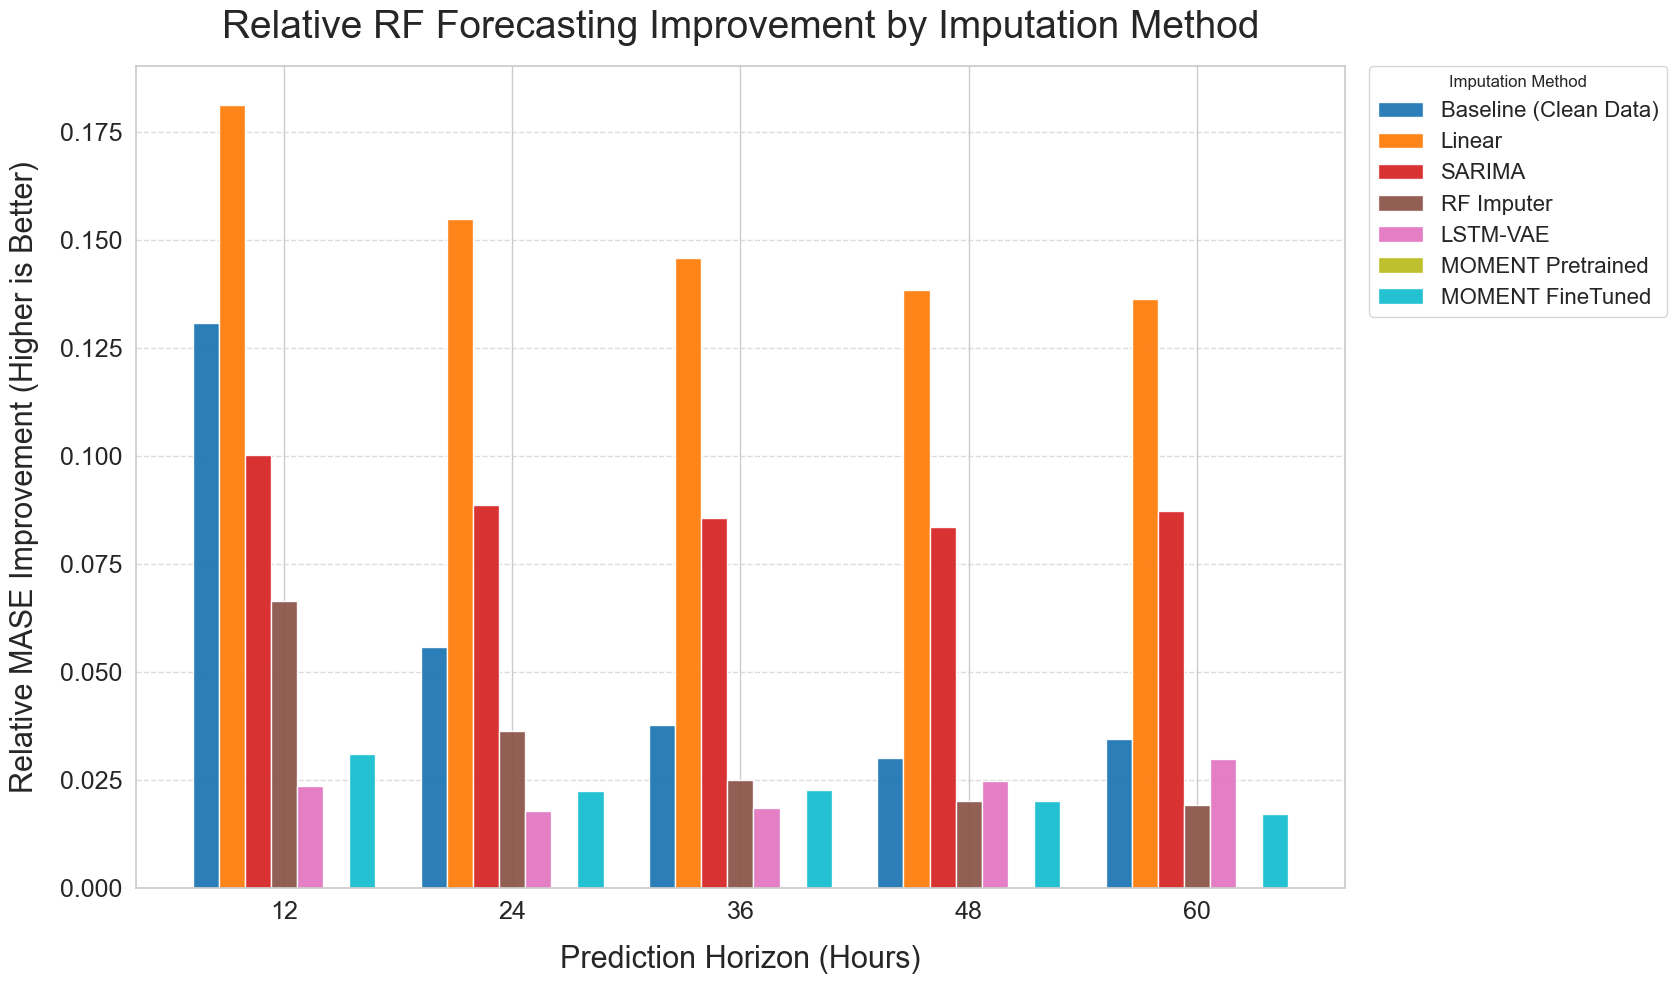

Gráfico de Rendimiento Relativo corregido guardado en: images\rf_forecast_performance_score_corrected.png


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

# --- 1. DATOS ---
# Usamos los datos que proporcionaste, que ya son un buen ejemplo.
data_string = """
Imputation_Method,Horizon_h,Global_Avg_MASE
Original_Data_Baseline,12,1.0852223798677307
Original_Data_Baseline,24,1.587032977515287
Original_Data_Baseline,36,1.8364371835192859
Original_Data_Baseline,48,1.9694791816775241
Original_Data_Baseline,60,2.052305551796945
LSTM-VAE,12,1.219121862329889
LSTM-VAE,24,1.6507777427354928
LSTM-VAE,36,1.873314485282413
LSTM-VAE,48,1.9805020373084008
LSTM-VAE,60,2.062203536422297
MOMENT Pretrained,12,1.2486698660919708
MOMENT Pretrained,24,1.680826038312254
MOMENT Pretrained,36,1.908632084782961
MOMENT Pretrained,48,2.0307995662589424
MOMENT Pretrained,60,2.1256162412149013
MOMENT FineTuned,12,1.209880312734452
MOMENT FineTuned,24,1.6431213133820632
MOMENT FineTuned,36,1.865447528089863
MOMENT FineTuned,48,1.9900230350071115
MOMENT FineTuned,60,2.088960119688581
Random Forest,12,1.1658101422256644
Random Forest,24,1.6196575747065158
Random Forest,36,1.8609239354255445
Random Forest,48,1.9900497780491326
Random Forest,60,2.0846508416186067
SARIMA,12,1.1234829124103527
SARIMA,24,1.5318415823068732
SARIMA,36,1.7450694585257103
SARIMA,48,1.8611670586590934
SARIMA,60,1.940232911075581
Linear Interpolation,12,1.0222434127283098
Linear Interpolation,24,1.4205737274734025
Linear Interpolation,36,1.6302839158280056
Linear Interpolation,48,1.7497245476244172
Linear Interpolation,60,1.8357627539963413
"""

df = pd.read_csv(io.StringIO(data_string))

# --- 2. PREPARACIÓN DE DATOS Y CÁLCULO DE LA MÉTRICA RELATIVA (LÓGICA CORREGIDA) ---

rename_map = {
    'Original_Data_Baseline': 'Baseline (Clean Data)',
    'Linear Interpolation': 'Linear',
    'Random Forest': 'RF Imputer',
    'MOMENT Pretrained': 'MOMENT Pretrained',
    'MOMENT Finetuned': 'MOMENT FineTuned'
}
df['Imputation_Method'] = df['Imputation_Method'].replace(rename_map)

df_pivot = df.pivot_table(index='Horizon_h', columns='Imputation_Method', values='Global_Avg_MASE')

# --- NUEVA LÓGICA: Calcular mejora relativa sobre el peor método en cada horizonte ---
# 1. Encontrar el MASE máximo (peor rendimiento) para cada horizonte (fila)
worst_mase_per_horizon = df_pivot.max(axis=1)

# 2. Calcular la mejora relativa: (MASE_peor - MASE_metodo) / MASE_peor
# Esto da un score donde más alto es mejor, y 0 es el peor.
df_performance_score = df_pivot.apply(lambda col: (worst_mase_per_horizon - col) / worst_mase_per_horizon, axis=0)

desired_order = [
    'Baseline (Clean Data)', 'Linear', 'SARIMA', 'RF Imputer', 
    'LSTM-VAE', 'MOMENT Pretrained', 'MOMENT FineTuned'
]
existing_columns_ordered = [col for col in desired_order if col in df_performance_score.columns]
df_performance_final = df_performance_score[existing_columns_ordered]

# --- 3. GENERACIÓN DEL GRÁFICO DE RENDIMIENTO RELATIVO ---

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (20, 10) # Ajustado para mejor proporción
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 16

ax = df_performance_final.plot(kind='bar', width=0.8, alpha=0.95, colormap='tab10')

# No se necesita una línea de referencia, ya que el "peor" método tendrá barras de altura 0
# y el mejor tendrá las barras más altas.

# Títulos y etiquetas
plt.title("Relative RF Forecasting Improvement by Imputation Method", fontsize=28, pad=20)
plt.xlabel("Prediction Horizon (Hours)", fontsize=22, labelpad=15)
plt.ylabel("Relative MASE Improvement (Higher is Better)", fontsize=22, labelpad=15)
plt.xticks(rotation=0)
plt.ylim(bottom=0) # Asegurar que el eje Y comience en 0
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mover la leyenda fuera del gráfico para mayor claridad
ax.legend(title='Imputation Method', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout(rect=[0, 0, 0.85, 1]) # Ajustar el layout para hacer espacio a la leyenda

# Guardar la figura
output_dir = "images"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "rf_forecast_performance_score_corrected.png")
plt.savefig(output_path, dpi=300)

plt.show()

print(f"Gráfico de Rendimiento Relativo corregido guardado en: {output_path}")

importancia SARIMAX

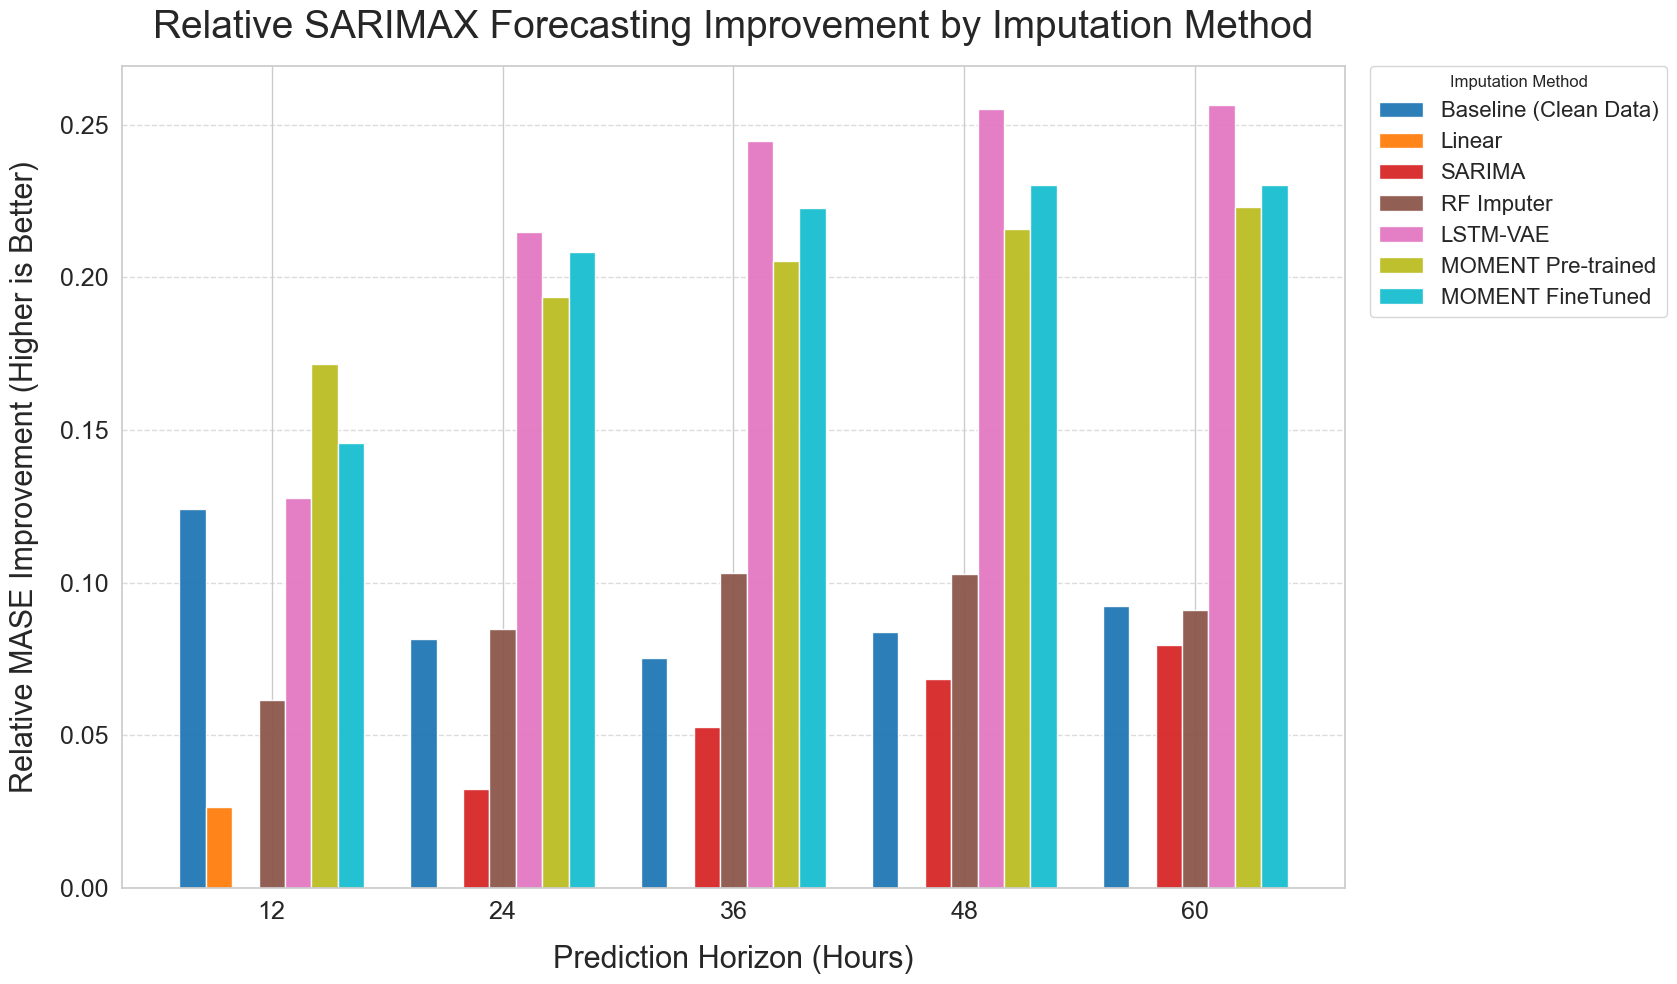

Gráfico de Rendimiento Relativo para SARIMAX guardado en: images\sarimax_forecast_performance_score.png


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

# --- 1. DATOS PARA EL PREDICTOR SARIMAX ---
data_string_sarimax = """
Imputation_Method,Horizon_h,Global_Avg_MASE
LSTM-VAE,12,3.3253693418427916
LSTM-VAE,24,5.172912094048996
LSTM-VAE,36,6.180985572347912
LSTM-VAE,48,6.604639317773188
LSTM-VAE,60,6.735351577856291
Linear Interpolation,12,3.7113849639293193
Linear Interpolation,24,6.589463141671279
Linear Interpolation,36,8.181440594064624
Linear Interpolation,48,8.867168291480477
Linear Interpolation,60,9.057363367426518
MOMENT FineTuned,12,3.2561324056554546
MOMENT FineTuned,24,5.21710857476963
MOMENT FineTuned,36,6.359020129984938
MOMENT FineTuned,48,6.82496625552491
MOMENT FineTuned,60,6.9711232532850005
MOMENT Pretrained,12,3.1577674978538894
MOMENT Pretrained,24,5.313579028207347
MOMENT Pretrained,36,6.502514245485852
MOMENT Pretrained,48,6.952923220084607
MOMENT Pretrained,60,7.038377518017222
Original_Data_Baseline,12,3.3395855917547537
Original_Data_Baseline,24,6.053126071845942
Original_Data_Baseline,36,7.565371546410067
Original_Data_Baseline,48,8.123773091299029
Original_Data_Baseline,60,8.221478431143181
Random Forest,12,3.5774752419943123
Random Forest,24,6.030727992758478
Random Forest,36,7.336704716224585
Random Forest,48,7.954343414879732
Random Forest,60,8.231532659334086
SARIMA,12,3.8121017804009165
SARIMA,24,6.376372085418265
SARIMA,36,7.749196175446394
SARIMA,48,8.261715688994974
SARIMA,60,8.335605089174086
"""

df = pd.read_csv(io.StringIO(data_string_sarimax))

# --- 2. PREPARACIÓN DE DATOS Y CÁLCULO DE LA MÉTRICA RELATIVA ---

rename_map = {
    'Original_Data_Baseline': 'Baseline (Clean Data)',
    'Linear Interpolation': 'Linear',
    'Random Forest': 'RF Imputer',
    'MOMENT Pretrained': 'MOMENT Pre-trained',
    'MOMENT FineTuned': 'MOMENT FineTuned'
}
df['Imputation_Method'] = df['Imputation_Method'].replace(rename_map)

df_pivot = df.pivot_table(index='Horizon_h', columns='Imputation_Method', values='Global_Avg_MASE')

# --- LÓGICA: Calcular mejora relativa sobre el peor método en cada horizonte ---
worst_mase_per_horizon = df_pivot.max(axis=1)
df_performance_score = df_pivot.apply(lambda col: (worst_mase_per_horizon - col) / worst_mase_per_horizon, axis=0)

desired_order = [
    'Baseline (Clean Data)', 'Linear', 'SARIMA', 'RF Imputer', 
    'LSTM-VAE', 'MOMENT Pre-trained', 'MOMENT FineTuned'
]
existing_columns_ordered = [col for col in desired_order if col in df_performance_score.columns]
df_performance_final = df_performance_score[existing_columns_ordered]

# --- 3. GENERACIÓN DEL GRÁFICO DE RENDIMIENTO RELATIVO ---

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (20, 10)
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 16

ax = df_performance_final.plot(kind='bar', width=0.8, alpha=0.95, colormap='tab10')

# Títulos y etiquetas
plt.title("Relative SARIMAX Forecasting Improvement by Imputation Method", fontsize=28, pad=20)
plt.xlabel("Prediction Horizon (Hours)", fontsize=22, labelpad=15)
plt.ylabel("Relative MASE Improvement (Higher is Better)", fontsize=22, labelpad=15)
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mover la leyenda fuera del gráfico
ax.legend(title='Imputation Method', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout(rect=[0, 0, 0.85, 1])

# Guardar la figura
output_dir = "images"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "sarimax_forecast_performance_score.png")
plt.savefig(output_path, dpi=300)

plt.show()

print(f"Gráfico de Rendimiento Relativo para SARIMAX guardado en: {output_path}")

importancia lstm

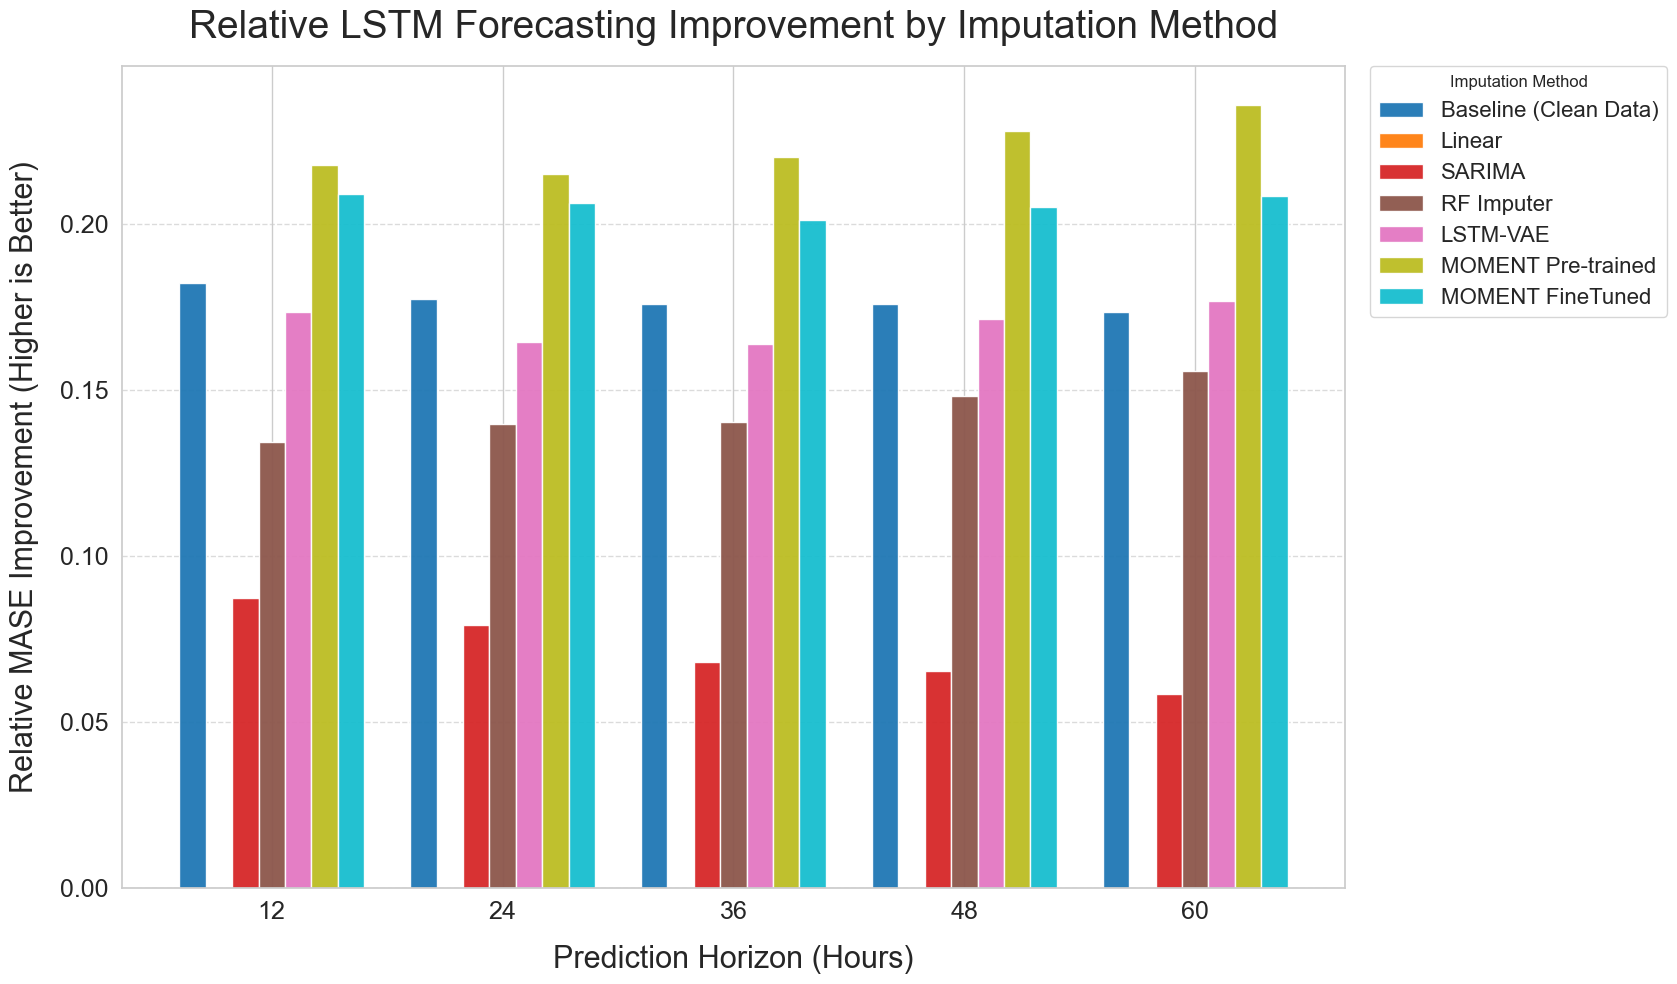

Gráfico de Rendimiento Relativo para LSTM guardado en: images\lstm_forecast_performance_score.png


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

# --- 1. DATOS PARA EL PREDICTOR LSTM ---
data_string_lstm = """
Imputation_Method,Horizon_h,Global_Avg_MASE
LSTM-VAE,12,9.441740125759592
LSTM-VAE,24,9.703177696322022
LSTM-VAE,36,9.804651020591486
LSTM-VAE,48,9.87799457547383
LSTM-VAE,60,9.934822620536547
Linear Interpolation,12,11.424112231379752
Linear Interpolation,24,11.61249585114093
Linear Interpolation,36,11.726452101611564
Linear Interpolation,48,11.9223090400934
Linear Interpolation,60,12.070298703152641
MOMENT FineTuned,12,9.035518871225808
MOMENT FineTuned,24,9.21805009340426
MOMENT FineTuned,36,9.366240075153893
MOMENT FineTuned,48,9.478396695672046
MOMENT FineTuned,60,9.553792831708527
MOMENT Pretrained,12,8.935162965626743
MOMENT Pretrained,24,9.11333267256509
MOMENT Pretrained,36,9.144057688258222
MOMENT Pretrained,48,9.202827638278213
MOMENT Pretrained,60,9.223753941466285
Original_Data_Baseline,12,9.341831150465636
Original_Data_Baseline,24,9.552227844251005
Original_Data_Baseline,36,9.664281087544586
Original_Data_Baseline,48,9.824279568645524
Original_Data_Baseline,60,9.97435818589861
Random Forest,12,9.888791549529541
Random Forest,24,9.98929214010517
Random Forest,36,10.081489457824137
Random Forest,48,10.154979430963847
Random Forest,60,10.189572371025257
SARIMA,12,10.426455093690386
SARIMA,24,10.69192955400288
SARIMA,36,10.929273071274743
SARIMA,48,11.143934017432063
SARIMA,60,11.365493002568737
"""

df = pd.read_csv(io.StringIO(data_string_lstm))

# --- 2. PREPARACIÓN DE DATOS Y CÁLCULO DE LA MÉTRICA RELATIVA ---

rename_map = {
    'Original_Data_Baseline': 'Baseline (Clean Data)',
    'Linear Interpolation': 'Linear',
    'Random Forest': 'RF Imputer',
    'MOMENT Pretrained': 'MOMENT Pre-trained',
    'MOMENT FineTuned': 'MOMENT FineTuned'
}
df['Imputation_Method'] = df['Imputation_Method'].replace(rename_map)

df_pivot = df.pivot_table(index='Horizon_h', columns='Imputation_Method', values='Global_Avg_MASE')

# --- LÓGICA: Calcular mejora relativa sobre el peor método en cada horizonte ---
worst_mase_per_horizon = df_pivot.max(axis=1)
df_performance_score = df_pivot.apply(lambda col: (worst_mase_per_horizon - col) / worst_mase_per_horizon, axis=0)

desired_order = [
    'Baseline (Clean Data)', 'Linear', 'SARIMA', 'RF Imputer', 
    'LSTM-VAE', 'MOMENT Pre-trained', 'MOMENT FineTuned'
]
existing_columns_ordered = [col for col in desired_order if col in df_performance_score.columns]
df_performance_final = df_performance_score[existing_columns_ordered]

# --- 3. GENERACIÓN DEL GRÁFICO DE RENDIMIENTO RELATIVO ---

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (20, 10)
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 16

ax = df_performance_final.plot(kind='bar', width=0.8, alpha=0.95, colormap='tab10')

# Títulos y etiquetas
plt.title("Relative LSTM Forecasting Improvement by Imputation Method", fontsize=28, pad=20)
plt.xlabel("Prediction Horizon (Hours)", fontsize=22, labelpad=15)
plt.ylabel("Relative MASE Improvement (Higher is Better)", fontsize=22, labelpad=15)
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mover la leyenda fuera del gráfico
ax.legend(title='Imputation Method', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout(rect=[0, 0, 0.85, 1])

# Guardar la figura
output_dir = "images"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "lstm_forecast_performance_score.png")
plt.savefig(output_path, dpi=300)

plt.show()

print(f"Gráfico de Rendimiento Relativo para LSTM guardado en: {output_path}")

importancia linear

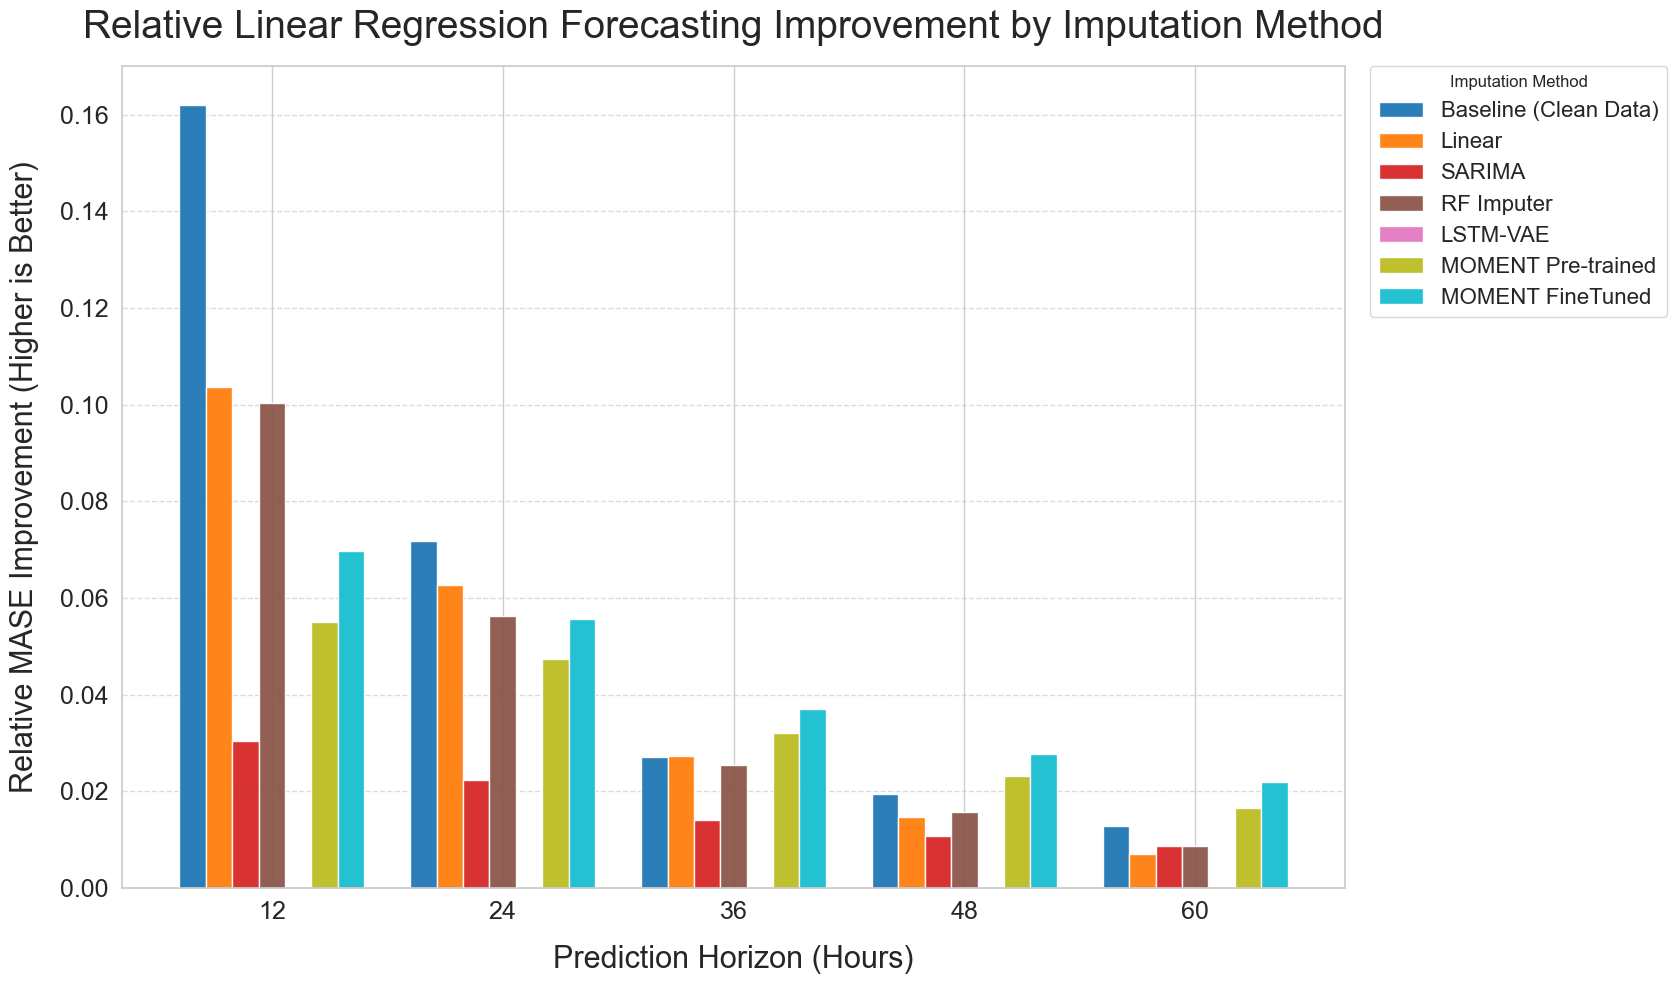

Gráfico de Rendimiento Relativo para Linear Regressor guardado en: images\linear_regressor_forecast_performance_score.png


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

# --- 1. DATOS PARA EL PREDICTOR LINEAR REGRESSOR ---
data_string_lr = """
Imputation_Method,Horizon_h,Global_Avg_MASE
LSTM-VAE,12,4.081807807561942
LSTM-VAE,24,5.604176215184671
LSTM-VAE,36,6.581893762558996
LSTM-VAE,48,6.855312322467438
LSTM-VAE,60,7.0215312297181836
Linear Interpolation,12,3.6588965844792543
Linear Interpolation,24,5.2523811744432285
Linear Interpolation,36,6.402130531771749
Linear Interpolation,48,6.7542594789141965
Linear Interpolation,60,6.972665587635531
MOMENT FineTuned,12,3.7970699927070686
MOMENT FineTuned,24,5.292387893062306
MOMENT FineTuned,36,6.338166410191037
MOMENT FineTuned,48,6.6646813921351
MOMENT FineTuned,60,6.866999395275851
MOMENT Pretrained,12,3.856928344201814
MOMENT Pretrained,24,5.338637434113208
MOMENT Pretrained,36,6.3704364693386815
MOMENT Pretrained,48,6.696779712275978
MOMENT Pretrained,60,6.905222660489631
Original_Data_Baseline,12,3.4205562291505855
Original_Data_Baseline,24,5.201907175184474
Original_Data_Baseline,36,6.403418196711037
Original_Data_Baseline,48,6.722022197841041
Original_Data_Baseline,60,6.931035608826417
Random Forest,12,3.672055075445849
Random Forest,24,5.289298374079725
Random Forest,36,6.414606797627773
Random Forest,48,6.747776868012449
Random Forest,60,6.960266975726047
SARIMA,12,3.9574580161246433
SARIMA,24,5.478874984855917
SARIMA,36,6.4893160189833665
SARIMA,48,6.781366226128906
SARIMA,60,6.96000544109861
"""

df = pd.read_csv(io.StringIO(data_string_lr))

# --- 2. PREPARACIÓN DE DATOS Y CÁLCULO DE LA MÉTRICA RELATIVA ---

rename_map = {
    'Original_Data_Baseline': 'Baseline (Clean Data)',
    'Linear Interpolation': 'Linear',
    'Random Forest': 'RF Imputer',
    'MOMENT Pretrained': 'MOMENT Pre-trained',
    'MOMENT FineTuned': 'MOMENT FineTuned'
}
df['Imputation_Method'] = df['Imputation_Method'].replace(rename_map)

df_pivot = df.pivot_table(index='Horizon_h', columns='Imputation_Method', values='Global_Avg_MASE')

# --- LÓGICA: Calcular mejora relativa sobre el peor método en cada horizonte ---
worst_mase_per_horizon = df_pivot.max(axis=1)
df_performance_score = df_pivot.apply(lambda col: (worst_mase_per_horizon - col) / worst_mase_per_horizon, axis=0)

desired_order = [
    'Baseline (Clean Data)', 'Linear', 'SARIMA', 'RF Imputer', 
    'LSTM-VAE', 'MOMENT Pre-trained', 'MOMENT FineTuned'
]
existing_columns_ordered = [col for col in desired_order if col in df_performance_score.columns]
df_performance_final = df_performance_score[existing_columns_ordered]

# --- 3. GENERACIÓN DEL GRÁFICO DE RENDIMIENTO RELATIVO ---

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (20, 10)
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 16

ax = df_performance_final.plot(kind='bar', width=0.8, alpha=0.95, colormap='tab10')

# Títulos y etiquetas
plt.title("Relative Linear Regression Forecasting Improvement by Imputation Method", fontsize=28, pad=20)
plt.xlabel("Prediction Horizon (Hours)", fontsize=22, labelpad=15)
plt.ylabel("Relative MASE Improvement (Higher is Better)", fontsize=22, labelpad=15)
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mover la leyenda fuera del gráfico
ax.legend(title='Imputation Method', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout(rect=[0, 0, 0.85, 1])

# Guardar la figura
output_dir = "images"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "linear_regressor_forecast_performance_score.png")
plt.savefig(output_path, dpi=300)

plt.show()

print(f"Gráfico de Rendimiento Relativo para Linear Regressor guardado en: {output_path}")

importancia moment pre

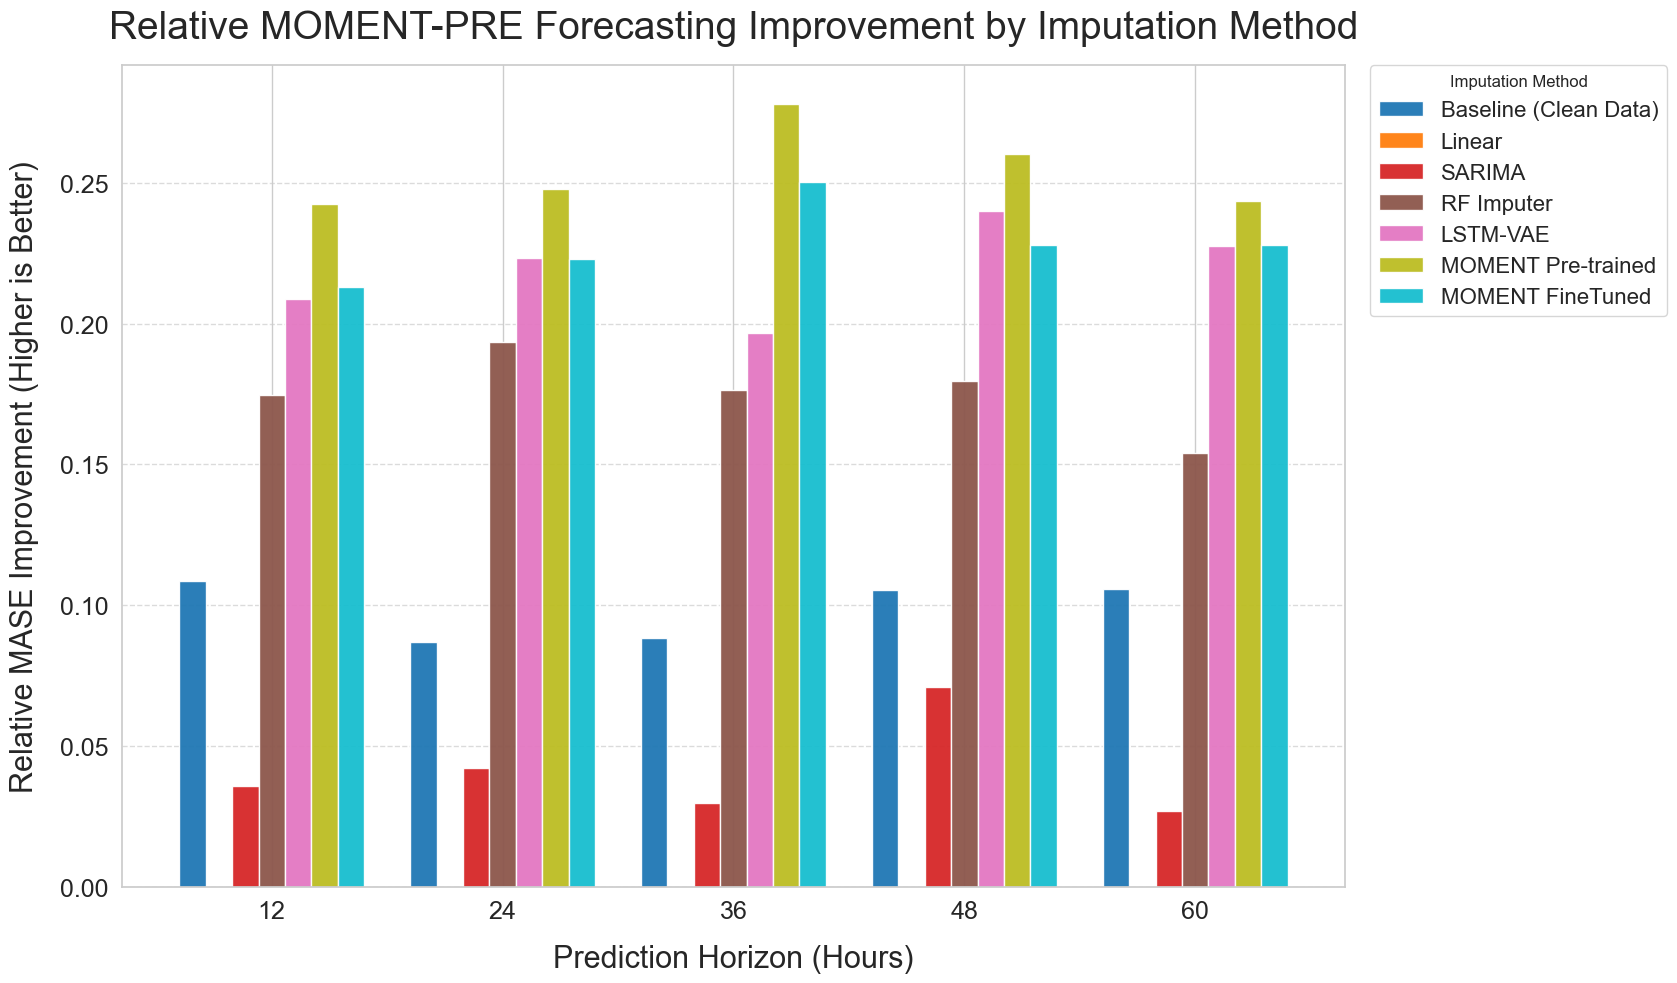

Gráfico de Rendimiento Relativo para MOMENT-PRE guardado en: images\moment_pre_forecast_performance_score.png


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

# --- 1. DATOS PARA EL PREDICTOR MOMENT PRE-ENTRENADO ---
data_string_moment_pre = """
Imputation_Method,Horizon_h,Global_Avg_MASE
LSTM-VAE,12,7.755090720032582
LSTM-VAE,24,8.971246637754207
LSTM-VAE,36,9.192119356804623
LSTM-VAE,48,8.717181484056397
LSTM-VAE,60,7.514027220421288
Linear Interpolation,12,9.801464010676039
Linear Interpolation,24,11.552079384971417
Linear Interpolation,36,11.443606175915681
Linear Interpolation,48,11.470926729073774
Linear Interpolation,60,9.72643119501331
MOMENT FineTuned,12,7.71343818510987
MOMENT FineTuned,24,8.97709134002173
MOMENT FineTuned,36,8.578829050718857
MOMENT FineTuned,48,8.857384564500286
MOMENT FineTuned,60,7.510792387941127
MOMENT Pretrained,12,7.4232740136871485
MOMENT Pretrained,24,8.688080138549568
MOMENT Pretrained,36,8.264047575189847
MOMENT Pretrained,48,8.485914836917757
MOMENT Pretrained,60,7.357378120145948
Original_Data_Baseline,12,8.737776393333972
Original_Data_Baseline,24,10.546531955852643
Original_Data_Baseline,36,10.433535918726736
Original_Data_Baseline,48,10.260932419395187
Original_Data_Baseline,60,8.69657242594939
Random Forest,12,8.090474660450955
Random Forest,24,9.315248892390521
Random Forest,36,9.425025437859905
Random Forest,48,9.412018473204395
Random Forest,60,8.227669224454296
SARIMA,12,9.449505488917437
SARIMA,24,11.06498900014105
SARIMA,36,11.104193588491961
SARIMA,48,10.658318378602267
SARIMA,60,9.462693838360215
"""

df = pd.read_csv(io.StringIO(data_string_moment_pre))

# --- 2. PREPARACIÓN DE DATOS Y CÁLCULO DE LA MÉTRICA RELATIVA ---

rename_map = {
    'Original_Data_Baseline': 'Baseline (Clean Data)',
    'Linear Interpolation': 'Linear',
    'Random Forest': 'RF Imputer',
    'MOMENT Pretrained': 'MOMENT Pre-trained',
    'MOMENT FineTuned': 'MOMENT FineTuned'
}
df['Imputation_Method'] = df['Imputation_Method'].replace(rename_map)

df_pivot = df.pivot_table(index='Horizon_h', columns='Imputation_Method', values='Global_Avg_MASE')

# --- LÓGICA: Calcular mejora relativa sobre el peor método en cada horizonte ---
worst_mase_per_horizon = df_pivot.max(axis=1)
df_performance_score = df_pivot.apply(lambda col: (worst_mase_per_horizon - col) / worst_mase_per_horizon, axis=0)

desired_order = [
    'Baseline (Clean Data)', 'Linear', 'SARIMA', 'RF Imputer', 
    'LSTM-VAE', 'MOMENT Pre-trained', 'MOMENT FineTuned'
]
existing_columns_ordered = [col for col in desired_order if col in df_performance_score.columns]
df_performance_final = df_performance_score[existing_columns_ordered]

# --- 3. GENERACIÓN DEL GRÁFICO DE RENDIMIENTO RELATIVO ---

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (20, 10)
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 16

ax = df_performance_final.plot(kind='bar', width=0.8, alpha=0.95, colormap='tab10')

# Títulos y etiquetas
plt.title("Relative MOMENT-PRE Forecasting Improvement by Imputation Method", fontsize=28, pad=20)
plt.xlabel("Prediction Horizon (Hours)", fontsize=22, labelpad=15)
plt.ylabel("Relative MASE Improvement (Higher is Better)", fontsize=22, labelpad=15)
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mover la leyenda fuera del gráfico
ax.legend(title='Imputation Method', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout(rect=[0, 0, 0.85, 1])

# Guardar la figura
output_dir = "images"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "moment_pre_forecast_performance_score.png")
plt.savefig(output_path, dpi=300)

plt.show()

print(f"Gráfico de Rendimiento Relativo para MOMENT-PRE guardado en: {output_path}")

importancia moment ft

prediccion cualitativa

In [1]:
# =============================================================================
# CELDA 1: GENERACIÓN DE PREDICCIONES CON MOMENT (RUTA RAÍZ CORREGIDA)
# =============================================================================

import pandas as pd
import numpy as np
import os
import torch
from momentfm import MOMENTPipeline
from sklearn.preprocessing import StandardScaler
import time
import glob
import warnings
from tqdm import tqdm
import joblib

warnings.filterwarnings("ignore")

# --- 1. Configuración ---
TARGET_VARIABLE = 'AQI'
CONTEXT_LENGTH = 512
HORIZON = 60
FORECASTING_MODELS_MOMENT = {
    'MOMENT Pre-trained': 'moment_pre',
    'MOMENT Fine-tuned': 'moment_ft'
}
SCENARIOS_TO_PROCESS = [
    {'city': 'Brasilia', 'imputation_method': 'MOMENT Pretrained', 'scenario': 'BlockRows_24h_20percent'},
    {'city': 'Sydney', 'imputation_method': 'MOMENT Pretrained', 'scenario': 'BlockRows_36h_20percent'},
    {'city': 'London', 'imputation_method': 'Random Forest', 'scenario': 'RandomRows_20percent'},
]

# --- Rutas Corregidas ---
PROJECT_ROOT_DIR = os.getcwd() # ¡CORRECCIÓN!
ORIGINAL_DATA_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
PREDICTIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'predicciones')
MOMENT_FT_METHOD_NAME = 'MOMENT_FT_Optimized' 
MOMENT_FT_ROOT_DIR = os.path.join(PREDICTIONS_BASE_DIR, MOMENT_FT_METHOD_NAME)
MOMENT_FT_MODEL_DIR = os.path.join(MOMENT_FT_ROOT_DIR, 'modelos')
MOMENT_FT_SCALER_DIR = os.path.join(MOMENT_FT_ROOT_DIR, 'scalers')
OUTPUT_DIR = os.path.join(PROJECT_ROOT_DIR, 'TFM_results', 'prediction_comparisons')
PREDICTIONS_CSV_DIR = os.path.join(OUTPUT_DIR, 'prediction_data')
os.makedirs(PREDICTIONS_CSV_DIR, exist_ok=True)

# --- Script Principal ---
if __name__ == '__main__':
    script_start_time = time.time()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"--- Generación de Predicciones MOMENT ---")
    print(f"Usando dispositivo: {device}")

    print("\nCargando modelos MOMENT...")
    moment_pre_predictor = MOMENTPipeline.from_pretrained("AutonLab/MOMENT-1-large", model_kwargs={'task_name': 'forecasting', 'forecast_horizon': HORIZON}).to(device)
    moment_pre_predictor.init()
    print("-> Modelo MOMENT Pre-trained cargado.")

    df_original_full = pd.read_csv(ORIGINAL_DATA_FILE)
    df_original_full['Date'] = pd.to_datetime(df_original_full['Date'])
    
    df_ground_truth_clean = df_original_full.copy()
    for col in df_ground_truth_clean.columns.drop(['Date', 'City', 'CO2']):
        if col in df_ground_truth_clean.columns:
            df_ground_truth_clean[col] = df_ground_truth_clean[col].interpolate(method='linear').ffill().bfill()

    for scenario_info in tqdm(SCENARIOS_TO_PROCESS, desc="Procesando Escenarios MOMENT"):
        city, imputation_method, scenario = scenario_info['city'], scenario_info['imputation_method'], scenario_info['scenario']
        city_safe, imputation_safe, scenario_safe = city.replace(" ", "_"), imputation_method.replace(" ", "_"), scenario.replace("/", "_").replace("\\", "_")
        
        imputed_csv_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method, 'CSVs', city_safe, scenario)
        imputed_files = glob.glob(os.path.join(imputed_csv_path, "*.csv"))

        if not imputed_files: 
            print(f"Advertencia: No se encontraron CSVs en: {imputed_csv_path}. Omitiendo.")
            continue
        
        df_imputed = pd.read_csv(imputed_files[0])
        df_imputed['Date'] = pd.to_datetime(df_imputed['Date'])

        df_ground_truth = df_ground_truth_clean[df_ground_truth_clean['City'] == city].copy()
        split_point = len(df_imputed) - 500
        context_df = df_imputed.iloc[split_point - CONTEXT_LENGTH : split_point]
        forecast_gt_df = df_ground_truth.iloc[split_point : split_point + HORIZON]

        for model_name, model_key in FORECASTING_MODELS_MOMENT.items():
            print(f"  -> Generando predicción para: {model_name}")
            model_name_safe = model_name.replace(" ", "_").replace("-", "_")
            
            if model_key == 'moment_pre':
                model_to_run = moment_pre_predictor
                scaler = StandardScaler().fit(context_df[[TARGET_VARIABLE]])
            elif model_key == 'moment_ft':
                model_path = os.path.join(MOMENT_FT_MODEL_DIR, f"moment_forecaster_ft_{city_safe}.pth")
                scaler_path = os.path.join(MOMENT_FT_SCALER_DIR, f"scaler_{city_safe}.joblib")
                if not (os.path.exists(model_path) and os.path.exists(scaler_path)): continue
                
                model_to_run = MOMENTPipeline.from_pretrained("AutonLab/MOMENT-1-base", model_kwargs={'task_name': 'forecasting', 'forecast_horizon': HORIZON}).to(device)
                model_to_run.init(); model_to_run.load_state_dict(torch.load(model_path, map_location=device))
                scaler = joblib.load(scaler_path)
            
            context_scaled = scaler.transform(context_df[[TARGET_VARIABLE]]).flatten()
            context_tensor = torch.tensor(context_scaled, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
            
            with torch.no_grad():
                outputs = model_to_run(x_enc=context_tensor, forecast_len=HORIZON)
                preds_scaled = outputs.forecast.cpu().squeeze().numpy()
                predictions = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()

            output_df = pd.DataFrame({'date': pd.concat([context_df['Date'], forecast_gt_df['Date']]).reset_index(drop=True), 'context': np.nan, 'ground_truth': np.nan, 'prediction': np.nan})
            output_df.loc[:len(context_df)-1, 'context'] = context_df[TARGET_VARIABLE].values
            output_df.loc[len(context_df):, 'ground_truth'] = forecast_gt_df[TARGET_VARIABLE].values
            output_df.loc[len(context_df):, 'prediction'] = predictions
            output_filename = f"prediction_{city_safe}_{imputation_safe}_{scenario_safe}_{model_name_safe}.csv"
            output_df.to_csv(os.path.join(PREDICTIONS_CSV_DIR, output_filename), index=False)
            print(f"    -> Predicción para {model_name} guardada.")
    
    print(f"\n--- Proceso MOMENT completado. Tiempo total: {(time.time() - script_start_time)/60:.2f} minutos. ---")

c:\Users\fdemiguel\AppData\Local\anaconda3\envs\moment_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Generación de Predicciones MOMENT ---
Usando dispositivo: cpu

Cargando modelos MOMENT...
-> Modelo MOMENT Pre-trained cargado.


Procesando Escenarios MOMENT:   0%|          | 0/3 [00:00<?, ?it/s]

  -> Generando predicción para: MOMENT Pre-trained
    -> Predicción para MOMENT Pre-trained guardada.
  -> Generando predicción para: MOMENT Fine-tuned


Procesando Escenarios MOMENT:  33%|███▎      | 1/3 [00:03<00:07,  3.99s/it]

    -> Predicción para MOMENT Fine-tuned guardada.
  -> Generando predicción para: MOMENT Pre-trained
    -> Predicción para MOMENT Pre-trained guardada.
  -> Generando predicción para: MOMENT Fine-tuned


Procesando Escenarios MOMENT:  67%|██████▋   | 2/3 [00:06<00:02,  2.97s/it]

    -> Predicción para MOMENT Fine-tuned guardada.
  -> Generando predicción para: MOMENT Pre-trained
    -> Predicción para MOMENT Pre-trained guardada.
  -> Generando predicción para: MOMENT Fine-tuned


Procesando Escenarios MOMENT: 100%|██████████| 3/3 [00:08<00:00,  2.78s/it]

    -> Predicción para MOMENT Fine-tuned guardada.

--- Proceso MOMENT completado. Tiempo total: 0.20 minutos. ---


In [1]:
# =============================================================================
# CELDA 1: GENERACIÓN DE PREDICCIONES CON MOMENT (RUTAS CORREGIDAS)
# =============================================================================

import pandas as pd
import numpy as np
import os
import torch
from momentfm import MOMENTPipeline
from sklearn.preprocessing import StandardScaler
import time
import glob
import warnings
from tqdm import tqdm
import joblib

warnings.filterwarnings("ignore")

# --- 1. Configuración ---
TARGET_VARIABLE = 'AQI'
CONTEXT_LENGTH = 512
HORIZON = 60
FORECASTING_MODELS_MOMENT = {
    'MOMENT Pre-trained': 'moment_pre',
    'MOMENT Fine-tuned': 'moment_ft'
}
SCENARIOS_TO_PROCESS = [
    {'city': 'Brasilia', 'imputation_method': 'MOMENT Pretrained', 'scenario': 'BlockRows_24h_20percent'},
    #{'city': 'Sydney', 'imputation_method': 'MOMENT Pretrained', 'scenario': 'BlockRows_36h_20percent'},
    #{'city': 'London', 'imputation_method': 'Random Forest', 'scenario': 'RandomRows_20percent'},
]

# --- Rutas Corregidas ---
PROJECT_ROOT_DIR = os.getcwd() 
ORIGINAL_DATA_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
PREDICTIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'predicciones')
MOMENT_FT_METHOD_NAME = 'MOMENT_FT_Optimized' 
MOMENT_FT_ROOT_DIR = os.path.join(PREDICTIONS_BASE_DIR, MOMENT_FT_METHOD_NAME)
MOMENT_FT_MODEL_DIR = os.path.join(MOMENT_FT_ROOT_DIR, 'modelos')
MOMENT_FT_SCALER_DIR = os.path.join(MOMENT_FT_ROOT_DIR, 'scalers')
OUTPUT_DIR = os.path.join(PROJECT_ROOT_DIR, 'TFM_results', 'prediction_comparisons')
PREDICTIONS_CSV_DIR = os.path.join(OUTPUT_DIR, 'prediction_data')
os.makedirs(PREDICTIONS_CSV_DIR, exist_ok=True)

# --- Script Principal ---
if __name__ == '__main__':
    script_start_time = time.time()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"--- Generación de Predicciones MOMENT ---")
    print(f"Usando dispositivo: {device}")

    print("\nCargando modelos MOMENT...")
    moment_pre_predictor = MOMENTPipeline.from_pretrained("AutonLab/MOMENT-1-large", model_kwargs={'task_name': 'forecasting', 'forecast_horizon': HORIZON}).to(device)
    moment_pre_predictor.init()
    print("-> Modelo MOMENT Pre-trained cargado.")

    df_original_full = pd.read_csv(ORIGINAL_DATA_FILE)
    df_original_full['Date'] = pd.to_datetime(df_original_full['Date'])
    
    df_ground_truth_clean = df_original_full.copy()
    for col in df_ground_truth_clean.columns.drop(['Date', 'City', 'CO2']):
        if col in df_ground_truth_clean.columns:
            df_ground_truth_clean[col] = df_ground_truth_clean[col].interpolate(method='linear').ffill().bfill()

    for scenario_info in tqdm(SCENARIOS_TO_PROCESS, desc="Procesando Escenarios MOMENT"):
        city, imputation_method, scenario = scenario_info['city'], scenario_info['imputation_method'], scenario_info['scenario']
        city_safe, imputation_safe, scenario_safe = city.replace(" ", "_"), imputation_method.replace(" ", "_"), scenario.replace("/", "_").replace("\\", "_")
        
        imputed_csv_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method, 'CSVs', city_safe, scenario)
        imputed_files = glob.glob(os.path.join(imputed_csv_path, "*.csv"))

        if not imputed_files: 
            print(f"Advertencia: No se encontraron CSVs en: {imputed_csv_path}. Omitiendo.")
            continue
        
        df_imputed = pd.read_csv(imputed_files[0])
        df_imputed['Date'] = pd.to_datetime(df_imputed['Date'])

        df_ground_truth = df_ground_truth_clean[df_ground_truth_clean['City'] == city].copy()
        split_point = len(df_imputed) - 500
        context_df = df_imputed.iloc[split_point - CONTEXT_LENGTH : split_point]
        forecast_gt_df = df_ground_truth.iloc[split_point : split_point + HORIZON]

        for model_name, model_key in FORECASTING_MODELS_MOMENT.items():
            print(f"  -> Generando predicción para: {model_name}")
            model_name_safe = model_name.replace(" ", "_").replace("-", "_")
            
            if model_key == 'moment_pre':
                model_to_run = moment_pre_predictor
                scaler = StandardScaler().fit(context_df[[TARGET_VARIABLE]])
            elif model_key == 'moment_ft':
                model_path = os.path.join(MOMENT_FT_MODEL_DIR, f"moment_forecaster_ft_{city_safe}.pth")
                scaler_path = os.path.join(MOMENT_FT_SCALER_DIR, f"scaler_{city_safe}.joblib")
                if not (os.path.exists(model_path) and os.path.exists(scaler_path)):
                    print(f"     [WARN] Modelo/Scaler FT no encontrado para {city}. Omitiendo.")
                    continue
                
                model_to_run = MOMENTPipeline.from_pretrained("AutonLab/MOMENT-1-base", model_kwargs={'task_name': 'forecasting', 'forecast_horizon': HORIZON}).to(device)
                model_to_run.init(); model_to_run.load_state_dict(torch.load(model_path, map_location=device))
                scaler = joblib.load(scaler_path)
            
            context_scaled = scaler.transform(context_df[[TARGET_VARIABLE]]).flatten()
            context_tensor = torch.tensor(context_scaled, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
            
            with torch.no_grad():
                outputs = model_to_run(x_enc=context_tensor, forecast_len=HORIZON)
                preds_scaled = outputs.forecast.cpu().squeeze().numpy()
                predictions = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()

            output_df = pd.DataFrame({'date': pd.concat([context_df['Date'], forecast_gt_df['Date']]).reset_index(drop=True), 'context': np.nan, 'ground_truth': np.nan, 'prediction': np.nan})
            output_df.loc[:len(context_df)-1, 'context'] = context_df[TARGET_VARIABLE].values
            output_df.loc[len(context_df):, 'ground_truth'] = forecast_gt_df[TARGET_VARIABLE].values
            output_df.loc[len(context_df):, 'prediction'] = predictions
            output_filename = f"prediction_{city_safe}_{imputation_safe}_{scenario_safe}_{model_name_safe}.csv"
            output_df.to_csv(os.path.join(PREDICTIONS_CSV_DIR, output_filename), index=False)
            print(f"    -> Predicción para {model_name} guardada.")
    
    print(f"\n--- Proceso MOMENT completado. Tiempo total: {(time.time() - script_start_time)/60:.2f} minutos. ---")

c:\Users\fdemiguel\AppData\Local\anaconda3\envs\moment_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Generación de Predicciones MOMENT ---
Usando dispositivo: cpu

Cargando modelos MOMENT...
-> Modelo MOMENT Pre-trained cargado.


Procesando Escenarios MOMENT:   0%|          | 0/1 [00:00<?, ?it/s]

  -> Generando predicción para: MOMENT Pre-trained
    -> Predicción para MOMENT Pre-trained guardada.
  -> Generando predicción para: MOMENT Fine-tuned


Procesando Escenarios MOMENT:   0%|          | 0/1 [00:04<?, ?it/s]


RuntimeError: Error(s) in loading state_dict for MOMENTPipeline:
	Unexpected key(s) in state_dict: "encoder.block.12.layer.0.SelfAttention.q.weight", "encoder.block.12.layer.0.SelfAttention.k.weight", "encoder.block.12.layer.0.SelfAttention.v.weight", "encoder.block.12.layer.0.SelfAttention.o.weight", "encoder.block.12.layer.0.layer_norm.weight", "encoder.block.12.layer.1.DenseReluDense.wi_0.weight", "encoder.block.12.layer.1.DenseReluDense.wi_1.weight", "encoder.block.12.layer.1.DenseReluDense.wo.weight", "encoder.block.12.layer.1.layer_norm.weight", "encoder.block.13.layer.0.SelfAttention.q.weight", "encoder.block.13.layer.0.SelfAttention.k.weight", "encoder.block.13.layer.0.SelfAttention.v.weight", "encoder.block.13.layer.0.SelfAttention.o.weight", "encoder.block.13.layer.0.layer_norm.weight", "encoder.block.13.layer.1.DenseReluDense.wi_0.weight", "encoder.block.13.layer.1.DenseReluDense.wi_1.weight", "encoder.block.13.layer.1.DenseReluDense.wo.weight", "encoder.block.13.layer.1.lay

In [ ]:
# =============================================================================
# CELDA 2: PREDICCIONES CLÁSICAS/ML, LSTM Y PLOTEO FINAL (RUTA CORREGIDA)
# =============================================================================

import pandas as pd
import numpy as np
import os
import time
import glob
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import json
import random
import re
import tensorflow as tf
from keras import layers, Model, callbacks
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")

# --- 1. Configuración ---
TARGET_VARIABLE = 'AQI'
EXOGENOUS_COLS = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
TIME_FEATURES = ['Hour', 'DayOfWeek', 'Month']
CONTEXT_LENGTH = 512
HORIZON = 60
HISTORY_LEN_FOR_PLOT = 100
N_LAGS_AQI, N_LAGS_EXO, N_LAGS_LSTM = 120, 120, 120
LSTM_UNITS, DROPOUT_RATE, LEARNING_RATE, CLIPNORM, EPOCHS, BATCH_SIZE = 32, 0.1, 0.001, 1.0, 5, 128
N_WFV_FOLDS, ES_PATIENCE, LR_PATIENCE = 2, 10, 5

FORECASTING_MODELS_TO_RUN = ['Linear Regression', 'SARIMAX', 'Random Forest', 'LSTM']
ALL_MODELS_FOR_PLOT = ['Linear Regression', 'SARIMAX', 'Random Forest', 'LSTM', 'MOMENT Pre-trained', 'MOMENT Fine-tuned']

SCENARIOS_TO_PROCESS = [
    {'city': 'Brasilia', 'imputation_method': 'MOMENT Pretrained', 'scenario': 'BlockRows_24h_20percent'},
    {'city': 'Sydney', 'imputation_method': 'MOMENT Pretrained', 'scenario': 'BlockRows_36h_20percent'},
    {'city': 'London', 'imputation_method': 'Random Forest', 'scenario': 'RandomRows_20percent'},
]

# --- Rutas Corregidas ---
PROJECT_ROOT_DIR = os.getcwd() 
ORIGINAL_DATA_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
ORDERS_JSON_INPUT_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones', 'SARIMA', 'model_orders')
OUTPUT_DIR = os.path.join(PROJECT_ROOT_DIR, 'TFM_results', 'prediction_comparisons')
PREDICTIONS_CSV_DIR = os.path.join(OUTPUT_DIR, 'prediction_data')
PLOTS_DIR = os.path.join(OUTPUT_DIR, 'plots')
MODELS_TEMP_DIR = os.path.join(OUTPUT_DIR, 'temp_models_lstm')
for d in [PREDICTIONS_CSV_DIR, PLOTS_DIR, MODELS_TEMP_DIR]: os.makedirs(d, exist_ok=True)

# --- 2. Funciones ---
def create_multivariate_lagged_features(df, target_col, exo_cols, time_cols, n_lags_target, n_lags_exo, horizon):
    df_copy, features = df.copy(), []
    for i in range(horizon, n_lags_target + horizon): features.append(df_copy[target_col].shift(i).rename(f'{target_col}_lag{i}'))
    for exo_col in exo_cols:
        if exo_col != target_col:
            for i in range(horizon, n_lags_exo + horizon): features.append(df_copy[exo_col].shift(i).rename(f'{exo_col}_lag{i}'))
    for tf_col in time_cols:
        if tf_col in df_copy.columns: features.append(df_copy[tf_col])
    return pd.concat(features, axis=1)

def create_lstm_sequences(input_data, target_data, n_lags, horizon):
    X, y = [], []
    end_idx = len(input_data) - n_lags - horizon + 1
    if end_idx <= 0: return np.array(X), np.array(y)
    for i in range(end_idx):
        X.append(input_data[i:(i + n_lags)])
        y.append(target_data[i + n_lags : i + n_lags + horizon].flatten())
    return np.array(X), np.array(y)

def get_sarimax_orders(city_name_safe):
    order_file_path = os.path.join(ORDERS_JSON_INPUT_DIR, f'orders_{city_name_safe}_{TARGET_VARIABLE}.json')
    try:
        with open(order_file_path, 'r') as f: orders = json.load(f)
        return tuple(orders['order']), tuple(orders['seasonal_order'])
    except Exception: return (1, 1, 1), (1, 1, 0, 24)

def run_rf_lr_prediction(model_name, df_imputed, forecast_gt_df, split_point, paths):
    X = create_multivariate_lagged_features(df_imputed, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI, N_LAGS_EXO, 1)
    y = df_imputed[TARGET_VARIABLE]
    train_data = pd.concat([X, y], axis=1).iloc[:split_point].dropna()
    X_train, y_train = train_data.drop(columns=[TARGET_VARIABLE]), train_data[TARGET_VARIABLE]
    X_forecast = X.loc[forecast_gt_df.index].ffill().bfill()
    if model_name == 'Random Forest':
        model = RandomForestRegressor(random_state=42, n_jobs=-1, n_estimators=100, max_depth=15, min_samples_split=5, min_samples_leaf=2, max_features='sqrt')
    else: model = LinearRegression()
    model.fit(X_train, y_train)
    return model.predict(X_forecast)

def run_sarimax_prediction(df_imputed, forecast_gt_df, split_point, paths):
    X = df_imputed[EXOGENOUS_COLS + TIME_FEATURES]
    y = df_imputed[TARGET_VARIABLE]
    X_train, y_train = X.iloc[:split_point], y.iloc[:split_point]
    X_forecast = X.loc[forecast_gt_df.index]
    order, seasonal_order = get_sarimax_orders(paths['city_safe'])
    model = SARIMAX(y_train, exog=X_train, order=order, seasonal_order=seasonal_order).fit(disp=False)
    return model.get_forecast(steps=HORIZON, exog=X_forecast).predicted_mean.values

def run_lstm_prediction(df_imputed, forecast_gt_df, split_point, paths):
    all_cols = EXOGENOUS_COLS + TIME_FEATURES + [TARGET_VARIABLE]
    scaler_all, scaler_target = MinMaxScaler(), MinMaxScaler()
    scaler_all.fit(df_imputed[all_cols].iloc[:split_point])
    scaler_target.fit(df_imputed[[TARGET_VARIABLE]].iloc[:split_point])
    scaled_data_all = scaler_all.transform(df_imputed[all_cols])
    scaled_data_target = scaler_target.transform(df_imputed[[TARGET_VARIABLE]])
    train_val_data, train_val_target = scaled_data_all[:split_point], scaled_data_target[:split_point]
    
    X_tv, y_tv = create_lstm_sequences(train_val_data, train_val_target, N_LAGS_LSTM, HORIZON)
    if len(X_tv) < 200: return np.array([np.nan] * HORIZON)
        
    tf.keras.backend.clear_session()
    inputs = layers.Input(shape=(N_LAGS_LSTM, X_tv.shape[2]))
    lstm1 = layers.LSTM(LSTM_UNITS, return_sequences=True)(inputs); dr1 = layers.Dropout(DROPOUT_RATE)(lstm1)
    lstm2 = layers.LSTM(LSTM_UNITS // 2)(dr1); dr2 = layers.Dropout(DROPOUT_RATE)(lstm2)
    outputs = layers.Dense(HORIZON)(dr2)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=CLIPNORM), loss='mae')
    
    model_path = os.path.join(MODELS_TEMP_DIR, f"lstm_{paths['city_safe']}_{paths['imputation_safe']}_{paths['scenario_safe']}.keras")
    if os.path.exists(model_path): os.remove(model_path)

    tscv = TimeSeriesSplit(n_splits=N_WFV_FOLDS)
    best_val_loss = float('inf')
    for train_idx, val_idx in tscv.split(X_tv):
        history = model.fit(X_tv[train_idx], y_tv[train_idx], validation_data=(X_tv[val_idx], y_tv[val_idx]), 
                            epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
                            callbacks=[callbacks.EarlyStopping(patience=ES_PATIENCE, restore_best_weights=True)])
        val_loss = min(history.history['val_loss'])
        if val_loss < best_val_loss: best_val_loss = val_loss; model.save(model_path)
            
    if not os.path.exists(model_path): return np.array([np.nan] * HORIZON)
    
    best_model = tf.keras.models.load_model(model_path)
    input_seq_scaled = scaler_all.transform(df_imputed[all_cols].iloc[split_point - N_LAGS_LSTM : split_point])
    prediction_scaled = best_model.predict(input_seq_scaled.reshape(1, N_LAGS_LSTM, -1), verbose=0)
    return scaler_target.inverse_transform(prediction_scaled).flatten()

def generate_comparison_plot_from_csvs(scenario_info, nan_file_path, base_csv_path, base_plot_path):
    city, imputation_method, scenario = scenario_info['city'], scenario_info['imputation_method'], scenario_info['scenario']
    print(f"--- Generando gráfico para: {city} | {imputation_method} | {scenario} ---")
    city_safe, imputation_safe, scenario_safe = city.replace(" ", "_"), imputation_method.replace(" ", "_"), scenario.replace("/", "_").replace("\\", "_")
    
    base_file_found = False
    for model_name_long in ALL_MODELS_FOR_PLOT:
        model_name_safe = model_name_long.replace(" ", "_").replace("-", "_")
        any_model_file = f"prediction_{city_safe}_{imputation_safe}_{scenario_safe}_{model_name_safe}.csv"
        if os.path.exists(os.path.join(base_csv_path, any_model_file)):
            df_base = pd.read_csv(os.path.join(base_csv_path, any_model_file))
            df_plot = df_base[['date', 'context', 'ground_truth']].copy(); df_plot['date'] = pd.to_datetime(df_plot['date'])
            base_file_found = True; break
    if not base_file_found: print(f"  Error: No se encontró archivo base para {scenario_info}."); return
        
    for model_name_long in ALL_MODELS_FOR_PLOT:
        model_name_safe = model_name_long.replace(" ", "_").replace("-", "_")
        pred_file = f"prediction_{city_safe}_{imputation_safe}_{scenario_safe}_{model_name_safe}.csv"
        try:
            df_pred = pd.read_csv(os.path.join(base_csv_path, pred_file)); df_plot[model_name_long] = df_pred['prediction']
        except FileNotFoundError: pass

    context_df = df_plot.dropna(subset=['context'])
    forecast_df = df_plot[df_plot['context'].isnull()]

    nan_mask_in_context = pd.Series(False, index=context_df.index)
    try:
        if nan_file_path and os.path.exists(nan_file_path):
            df_with_nans = pd.read_csv(nan_file_path)
            original_nan_indices = df_with_nans[df_with_nans[TARGET_VARIABLE].isnull()].index
            nan_mask_in_context = context_df.index.isin(original_nan_indices)
        else: print(f"  Advertencia: Archivo con NaNs no encontrado en la ruta: {nan_file_path}")
    except Exception as e: print(f"  Advertencia: No se pudo cargar el archivo con NaNs. Error: {e}")

    context_to_plot_df = context_df.tail(HISTORY_LEN_FOR_PLOT)
    nan_mask_to_plot = nan_mask_in_context[-HISTORY_LEN_FOR_PLOT:]
    
    plt.figure(figsize=(20, 8)); sns.set_theme(style="whitegrid")
    
    plt.plot(context_to_plot_df.date, context_to_plot_df.context, label='Observed History', color='black', linewidth=2.0, zorder=2)
    imputed_points = context_to_plot_df[nan_mask_to_plot]
    if not imputed_points.empty:
        plt.scatter(imputed_points.date, imputed_points.context, color='orange', s=60, zorder=3, label='Imputed History Point', edgecolors='black')
    
    plt.plot(forecast_df.date, forecast_df.ground_truth, label='Ground Truth', color='red', linewidth=2.5, linestyle='--')
    
    colors = sns.color_palette("tab10", n_colors=len(ALL_MODELS_FOR_PLOT))
    for i, col in enumerate([m for m in ALL_MODELS_FOR_PLOT if m in forecast_df.columns]):
        plt.plot(forecast_df.date, forecast_df[col], label=col, linewidth=2, alpha=0.9, color=colors[i])
        
    plt.title(f"Forecast Comparison in {city} (Imputation: {imputation_method})\nScenario: {scenario}", fontsize=22)
    plt.xlabel("Date", fontsize=18); plt.ylabel("AQI Value", fontsize=18)
    plt.legend(fontsize=14, loc='upper left'); plt.grid(True, which='both', linestyle='--', linewidth=0.5); plt.tight_layout()
    plot_filename = f"comparison_with_imputed_{city_safe}_{imputation_safe}_{scenario_safe}.png"
    plt.savefig(os.path.join(base_plot_path, plot_filename), dpi=150); plt.close()
    print(f"  Gráfico guardado en: {os.path.join(base_plot_path, plot_filename)}")


# --- 3. Script Principal ---
if __name__ == '__main__':
    script_start_time = time.time()
    
    df_original_full = pd.read_csv(ORIGINAL_DATA_FILE)
    df_original_full['Date'] = pd.to_datetime(df_original_full['Date'], utc=True)
    if 'CO2' in df_original_full.columns: df_original_full = df_original_full.drop(columns=['CO2'])
    df_original_full['Hour'] = df_original_full['Date'].dt.hour
    df_original_full['DayOfWeek'] = df_original_full['Date'].dt.dayofweek
    df_original_full['Month'] = df_original_full['Date'].dt.month
    
    df_ground_truth_clean = df_original_full.copy()
    for col in df_ground_truth_clean.columns.drop(['Date', 'City']):
        if col in df_ground_truth_clean.columns:
            df_ground_truth_clean[col] = df_ground_truth_clean[col].interpolate(method='linear').ffill().bfill()
        
    print("\n--- Iniciando generación de datos de predicción para modelos Clásicos/ML/LSTM ---")
    for scenario_info in tqdm(SCENARIOS_TO_PROCESS, desc="Procesando Escenarios"):
        city, imputation_method, scenario = scenario_info['city'], scenario_info['imputation_method'], scenario_info['scenario']
        city_safe, imputation_safe, scenario_safe = city.replace(" ", "_"), imputation_method.replace(" ", "_"), scenario.replace("/", "_").replace("\\", "_")
        
        imputed_csv_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method, 'CSVs', city_safe, scenario)
        imputed_files = glob.glob(os.path.join(imputed_csv_path, "*.csv"))
        if not imputed_files: continue
        
        df_imputed = pd.read_csv(imputed_files[0])
        df_imputed['Date'] = pd.to_datetime(df_imputed['Date'], utc=True)
        df_imputed['Hour'], df_imputed['DayOfWeek'], df_imputed['Month'] = df_imputed['Date'].dt.hour, df_imputed['Date'].dt.dayofweek, df_imputed['Date'].dt.month
        
        # --- LÓGICA CORREGIDA PARA ENCONTRAR EL ARCHIVO DE NANS ---
        rep_file_base = os.path.basename(imputed_files[0])
        match = re.search(r'(_rep\d+_seed\d+)', rep_file_base)
        nan_file_path_for_plot = None
        if match:
            base_name_parts = rep_file_base.split(match.group(1))
            if len(base_name_parts) > 0:
                base_name = base_name_parts[0]
                nan_filename = f"{base_name}{match.group(1)}_with_nans.csv"
                nan_file_path_for_plot = os.path.join(SIMULATED_DATA_ROOT_DIR, city_safe, scenario, nan_filename)

        df_ground_truth = df_ground_truth_clean[df_ground_truth_clean['City'] == city].copy()
        split_point = len(df_imputed) - 500
        context_df = df_imputed.iloc[split_point - CONTEXT_LENGTH : split_point]
        forecast_gt_df = df_ground_truth.iloc[split_point : split_point + HORIZON]
        
        for model_name in FORECASTING_MODELS_TO_RUN:
            print(f"  -> Generando predicción para: {model_name} en {city}/{scenario}")
            paths = {'city_safe': city_safe, 'imputation_safe': imputation_safe, 'scenario_safe': scenario_safe}
            if model_name == 'LSTM':
                predictions = run_lstm_prediction(df_imputed, forecast_gt_df, split_point, paths)
            elif model_name == 'SARIMAX':
                predictions = run_sarimax_prediction(df_imputed, forecast_gt_df, split_point, paths)
            else:
                predictions = run_rf_lr_prediction(model_name, df_imputed, forecast_gt_df, split_point, paths)
            
            model_name_safe = model_name.replace(" ", "_").replace("-", "_")
            output_df = pd.DataFrame({'date': pd.concat([context_df['Date'], forecast_gt_df['Date']]).reset_index(drop=True), 'context': np.nan, 'ground_truth': np.nan, 'prediction': np.nan})
            output_df.loc[:len(context_df)-1, 'context'] = context_df[TARGET_VARIABLE].values
            output_df.loc[len(context_df):, 'ground_truth'] = forecast_gt_df[TARGET_VARIABLE].values
            output_df.loc[len(context_df):, 'prediction'] = predictions
            output_filename = f"prediction_{city_safe}_{imputation_safe}_{scenario_safe}_{model_name_safe}.csv"
            output_df.to_csv(os.path.join(PREDICTIONS_CSV_DIR, output_filename), index=False)
            print(f"    -> Predicción para {model_name} guardada.")
            
    print("\n--- Proceso de generación de datos de predicción completado. ---")

    print("\n--- Iniciando generación de gráficos comparativos desde archivos CSV ---")
    for scenario_info in tqdm(SCENARIOS_TO_PROCESS, desc="Generando Gráficos Comparativos"):
        city, imputation_method, scenario = scenario_info['city'], scenario_info['imputation_method'], scenario_info['scenario']
        city_safe, scenario_safe = city.replace(" ", "_"), scenario.replace("/", "_").replace("\\", "_")
        
        imputed_csv_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method, 'CSVs', city_safe, scenario)
        imputed_files = glob.glob(os.path.join(imputed_csv_path, "*.csv"))
        nan_file_path_for_plot = None
        if imputed_files:
            rep_file_base = os.path.basename(imputed_files[0])
            match = re.search(r'(_rep\d+_seed\d+)', rep_file_base)
            if match:
                base_name = rep_file_base.split(match.group(1))[0]
                nan_filename = f"{base_name}{match.group(1)}_with_nans.csv"
                nan_file_path_for_plot = os.path.join(SIMULATED_DATA_ROOT_DIR, city_safe, scenario, nan_filename)

        generate_comparison_plot_from_csvs(scenario_info, PREDICTIONS_CSV_DIR, PLOTS_DIR, nan_file_path_for_plot)

    print("\n--- Proceso completado. ---")
    script_end_time = time.time()
    print(f"Tiempo total: {(script_end_time - script_start_time)/60:.2f} minutos.")